---
# Experiments on berts embedding layer

---
## Setup S1 Vocab

Imports

In [1]:
from datasets import load_dataset, concatenate_datasets
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import (BertTokenizerFast,BertForSequenceClassification)
from matplotlib import colors as mcolors
from IPython.display import HTML, display
from sklearn.cluster import KMeans
from torch.utils.data import DataLoader
import os
import re
from collections import defaultdict
from sklearn.manifold import TSNE
from wordcloud import WordCloud
from sklearn.manifold import TSNE
from transformers import BertModel, BertTokenizerFast
from sklearn.metrics.pairwise import cosine_distances, euclidean_distances
from sklearn.decomposition import PCA



/Users/leosteiner/Desktop/transformer-shortcut-mitigation/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Load Model + Tokenizer 
Finetuned and Pre-Trained Bert (Same Tokenizer)

In [2]:
model_path = "./bert-finetuned" # "./bert-finetuned-v4"

tokenizer = BertTokenizerFast.from_pretrained(model_path)
model = BertForSequenceClassification.from_pretrained(model_path)

pretrained_name = "bert-base-uncased"
pt_bert = BertModel.from_pretrained(pretrained_name)

Load Dataset

In [3]:
# Load dataset
dataset = load_dataset('imdb')
train_data = dataset["train"]
test_data = dataset["test"]


Device Setup

In [4]:
# Device setup
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
# move to device
model.to(device)

#eval mode
model.eval()

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.5, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.5, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e

L2 Saliency Method per text example

In [5]:
def grad_l2_saliency(
    text: str,
    model,
    tokenizer,
    device,
    target_class = None,
    max_length = 512
):
    """
    Compute Grad-L2 saliency for one input text.

    Returns:
        tokens: list[str]          # wordpiece tokens incl. special tokens
        saliency: np.ndarray       # shape (seq_len,)
        input_ids: np.ndarray      # token ids (same length as saliency)
    """
    model.eval()

    # 1) Tokenize
    enc = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=max_length
    )
    input_ids = enc["input_ids"].to(device)           # [1, L] L = sequence length
    attention_mask = enc["attention_mask"].to(device) # [1, L]
    token_type_ids = enc.get("token_type_ids")
    if token_type_ids is not None:
        token_type_ids = token_type_ids.to(device)

    # 2) Get word embeddings and make them a leaf tensor with grad
    with torch.no_grad():
        word_embeds = model.bert.embeddings.word_embeddings(input_ids)
    word_embeds = word_embeds.detach().requires_grad_(True)  # [1, L, H]

    # 3) Forward pass using inputs_embeds so we can backprop to embeddings
    model.zero_grad()
    outputs = model(
        inputs_embeds=word_embeds, #pass embeddings instead of input_ids
        attention_mask=attention_mask,
        token_type_ids=token_type_ids
    )
    logits = outputs.logits  # [1, num_labels]

    # 4) Choose the logit to explain: pick predicted label by default
    if target_class is None:
        target_class = logits.argmax(dim=-1).item()  # predicted label

    # using the predicted class as scalar for autograd
    score = logits[0, target_class] # standard tensor indexing: tensor[row_index, column_index]

    # 5) Backward: d score / d word_embeds # computes gradients of score with respect to all tensors that have requires_grad=True in the computation graph.
    score.backward()

    grads = word_embeds.grad  # [1, L, H] store gradient 

    # 6) L2 norm over hidden dimension -> one score per token
    saliency = torch.norm(grads, p=2, dim=-1).squeeze(0)  # [1,L,H ] -> [1,L] -> [L] collapsing H

    # 7) Move to CPU / numpy
    saliency = saliency.detach().cpu().numpy()
    input_ids_cpu = input_ids.squeeze(0).detach().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(input_ids_cpu)

    return tokens, saliency, input_ids_cpu


Sentiment Prediction to prepare subsets of positve and negative predictions

In [6]:
def predict_labels(dataset_split, model, tokenizer, device, batch_size=32, max_length=512):
    """Function for model prediction."""
    model.eval()
    loader = DataLoader(dataset_split, batch_size=batch_size, shuffle=False)

    all_preds = []
    with torch.no_grad():
        for batch in loader:
            texts = batch["text"]
            enc = tokenizer(
                list(texts),
                return_tensors="pt",
                truncation=True,
                padding=True,
                max_length=max_length,
            ).to(device)

            logits = model(**enc).logits  # [B, 2]
            preds = logits.argmax(dim=-1).cpu()
            all_preds.extend(preds.tolist())

    return all_preds

path = "test_preds.npy"

if os.path.exists(path):
    test_preds = np.load(path)
else:
    test_preds = predict_labels(test_data, model, tokenizer, device)
    np.save(path, test_preds)


**Build S1-Vocab**

This function converts the first n text examples into their salience-fingerprints (S1 vectors), stacks those into a matrix, normalizes them, and returns both the matrix and the original texts.

One text example == one row

<pre>
          column dimension → |V| (the r vector)
        ┌──────────────────────────────────────────────┐
 row 1  │ r(1)[0]   r(1)[1]   r(1)[2]   ...   r(1)[V-1]│
 row 2  │ r(2)[0]   r(2)[1]   r(2)[2]   ...   r(2)[V-1]│
   .    │    .         .         .              .      │
 row N  │ r(N)[0]   r(N)[1]   r(N)[2]   ...   r(N)[V-1]│
        └──────────────────────────────────────────────┘
             ↑
             vocabulary-dimension (S1 vector)***
<pre>



In [7]:
def saliency_to_vocab_vector(input_ids, saliency, vocab_size, top_k=5):
    """
    Build a row-normalized vocabulary salience matrix for a dataset split.

    Returns:
        R_vocab: Array of shape [N, vocab_size] with one normalized salience vector per text.
        texts: List of the N source texts used to build the matrix.
    """

    r = np.zeros(vocab_size, dtype=np.float32) #expecting vocab size of bert tokenzier

    for tok_id, s in zip(input_ids, saliency):
        tok_id = int(tok_id)
        r[tok_id] = max(r[tok_id], abs(float(s))) # get max saliency value

    if top_k is not None and top_k < vocab_size:
        # Keep only top-k entries, zero out the rest
        if np.count_nonzero(r) > top_k: # count how many positoons in r are not zero
            top_idx = np.argpartition(r, -top_k)[-top_k:] # Find the indices of the k largest values in r, argsort begin nlogn efficient
            mask = np.zeros_like(r)
            mask[top_idx] = r[top_idx]
            r = mask

    return r


def build_salience_vocab_matrix_from_indices(
    dataset_split,
    indices,
    model,
    tokenizer,
    device,
    top_k=5,
    max_length=512,
):
    """
    Build a row-normalized vocabulary salience matrix for the selected dataset indices.

    Returns:
        R_vocab: Array of shape [N, vocab_size] with one normalized salience vector per selected text.
        texts: List of the N source texts corresponding to the selected indices.
    """
    
    vocab_size = tokenizer.vocab_size
    R_rows = []
    texts = []

    for idx in tqdm(indices):
        text = dataset_split[idx]["text"]
        tokens, sal, ids = grad_l2_saliency(
            text, model, tokenizer, device, max_length=max_length
        )
        r = saliency_to_vocab_vector(ids, sal, vocab_size, top_k=top_k)
        R_rows.append(r)
        texts.append(text)

    R_vocab = np.stack(R_rows, axis=0)
    # row-wise L2 normalization as in the paper
    norms = np.linalg.norm(R_vocab, axis=1, keepdims=True) + 1e-12
    R_vocab = R_vocab / norms
    return R_vocab, texts

Prepare Clustering

In [8]:
def cluster_salience(R_vocab, n_clusters=5, random_state=0):
    """Cluster salience vectors with k-means and return cluster assignments and the fitted model."""
    
    kmeans = KMeans(n_clusters=n_clusters, random_state=random_state)
    cluster_ids = kmeans.fit_predict(R_vocab)
    return cluster_ids, kmeans


---
## Extract tokens high salient-tokens

Inspect clusters wth top-most salient vocab items

**Pipeline Overview:**
<pre>
raw text
  ↓
token-level salience (Grad-L2)
  ↓
per-example vocab vector rᵢ ∈ ℝ^{|V|}
  ↓
stack rows → R_vocab ∈ ℝ^{N×|V|}
  ↓
K-Means on rows
  ↓
cluster_ids ∈ ℝ^{N}
  ↓
group rows by cluster
  ↓
select rows → cluster_matrix ∈ ℝ^{Nc×|V|}
  ↓
One of four methods to extract tokens
</pre>

**Methods**
1. top_token_cluster_agg: Top Saliency Tokens aggregated over all rows per cluster
2. top_token_cluster_max: Top Saliency Tokens (max val) per cluster
3. top_token_global_agg: Top Saliency Tokens aggregated
4. top_tokens_global_max: Top Saliency Tokens (max val)

In [9]:
def top_tokens_per_cluster_agg(R_vocab, cluster_ids, tokenizer, top_n=20, exclude_special=False):
    """
    Return the top top_n tokens per cluster by summed saliency (columns).

    For each cluster, saliency scores are summed across all assigned examples
    and the highest scoring tokens are returned as
    (token_id, token_string, score) tuples.
    """

    n_clusters = int(cluster_ids.max()) + 1
    results = {}
    
    # removing: [UNK][SEP][PAD][CLS][MASK]
    special_ids = set(tokenizer.all_special_ids) if exclude_special else set()

    # iterate clusters
    for c in range(n_clusters):
        idx = np.where(cluster_ids == c)[0]
        if len(idx) == 0:
            results[c] = []
            continue

        # Aggregate saliency over columns
        agg = R_vocab[idx].sum(axis=0)  # shape: (vocab_size,)
        agg = np.asarray(agg).reshape(-1)

        # zero out special tokens
        if exclude_special:
            agg[list(special_ids)] = 0.0

        top_ids = np.argsort(-agg)[:top_n]
        top_scores = agg[top_ids]
        top_toks = tokenizer.convert_ids_to_tokens(top_ids.tolist())

        results[c] = list(zip(top_ids.tolist(), top_toks, top_scores.tolist()))
    return results

def top_tokens_per_cluster_max(R_vocab, cluster_ids, tokenizer, top_n=20, exclude_special=False):
    """
    Return the top top_n tokens per cluster by maximum saliency( over columns).

    For each cluster, this takes the maximum saliency value for each token
    across all assigned examples and returns the highest-scoring tokens as
    (token_id, token_string, score) tuples.
    """

    n_clusters = int(cluster_ids.max()) + 1
    results = {}

    special_ids = set(tokenizer.all_special_ids) if exclude_special else set()

    # helper: robust row-subset max for dense or sparse
    def _colwise_max(mat):
        # scipy sparse matrices have .max(axis=0)
        if hasattr(mat, "tocoo"):  # crude but effective sparse check
            m = mat.max(axis=0)              # 1 x V
            return np.asarray(m).reshape(-1) # -> (V,)
        else:
            return np.max(mat, axis=0)

    for c in range(n_clusters):
        idx = np.where(cluster_ids == c)[0]
        if len(idx) == 0:
            results[c] = []
            continue

        col_max = _colwise_max(R_vocab[idx])  # shape: (vocab_size,)

        if exclude_special:
            col_max[list(special_ids)] = 0.0

        top_ids = np.argsort(-col_max)[:top_n]
        top_scores = col_max[top_ids]
        top_toks = tokenizer.convert_ids_to_tokens(top_ids.tolist())

        results[c] = list(zip(top_ids.tolist(), top_toks, top_scores.tolist()))

    return results

def top_tokens_global_agg(R_vocab, tokenizer, top_n=50, exclude_special=False):
    """
    Return the top_n tokens by summed saliency over all examples.

    This sums saliency scores column-wise across R_vocab and returns the
    highest-scoring tokens as (token_id, token_string, score) tuples.
    """

    # Column-wise sum over all examples -> shape (vocab_size,)
    agg = R_vocab.sum(axis=0)

    # Ensure flat dense 1D array
    agg = np.asarray(agg).reshape(-1)

    if exclude_special:
        special_ids = tokenizer.all_special_ids
        agg[special_ids] = 0.0

    top_ids = np.argsort(-agg)[:top_n]
    top_scores = agg[top_ids]
    top_toks = tokenizer.convert_ids_to_tokens(top_ids.tolist())

    return list(zip(top_ids.tolist(), top_toks, top_scores.tolist()))


def top_tokens_global_max(R_vocab, tokenizer, top_n=50, exclude_special=False):
    """
    Return the top top_n tokens by maximum saliency over all examples.

    This takes the column-wise maximum over R_vocab and returns the
    highest-scoring tokens as (token_id, token_string, score) tuples.
    """
    
    # Column-wise max over all rows -> shape (vocab_size,)
    max_vals = R_vocab.max(axis=0)

    # Ensure a flat dense 1D array (handles sparse matrices / numpy matrices)
    max_vals = np.asarray(max_vals).reshape(-1)

    if exclude_special:
        special_ids = tokenizer.all_special_ids
        max_vals[special_ids] = 0.0

    top_ids = np.argsort(-max_vals)[:top_n]
    top_scores = max_vals[top_ids]
    top_toks = tokenizer.convert_ids_to_tokens(top_ids.tolist())

    return list(zip(top_ids.tolist(), top_toks, top_scores.tolist()))

## Project most salient token into Finetuned Embedding space and Pre-Trained Embedding Space

Embedding tables

In [10]:
def get_embeddings_from_ids(token_ids, emb_table):
    """Return embedding vectors for the given token ids."""

    token_ids = np.asarray(token_ids, dtype=np.int64)
    return emb_table[token_ids]  # (n_tokens, hidden_dim)

def extract_token_ids_and_tokens(cluster_top,embedding_table):
    """
    Extract token ids and token strings, then return their embeddings.

    Accepts either a cluster-to-token mapping or a flat token list and
    returns `(token_ids, tokens, embeddings)`.
    """
    
    token_ids = []
    tokens = []

    if isinstance(cluster_top, dict):
        for items in cluster_top.values():
            for tid, tok, _ in items:
                token_ids.append(tid)
                tokens.append(tok)
    else:
        for tid, tok, _ in cluster_top:
                token_ids.append(tid)
                tokens.append(tok)


    token_ids = np.asarray(token_ids, dtype=np.int64)
    embeddings = get_embeddings_from_ids(token_ids, embedding_table)  # shape (N, hidden_dim)

    return token_ids, tokens, embeddings

emb_table_pretrained = pt_bert.get_input_embeddings().weight.detach().to("cpu")  # (vocab_size, hidden)
emb_table_finetuned = model.get_input_embeddings().weight.detach().to("cpu")

**Inpsect Embedding-Layer-Shift Finetuned -> Pre-Trained**
(cosine distance)

---

Negative Subset

---

In [11]:
# select indices of negatively predicted examples
neg_indices = [i for i, p in enumerate(test_preds) if p == 0]  

# sample 2500 
np.random.seed(42)
sample_size = min(2500, len(neg_indices))
neg_sample_indices = np.random.choice(neg_indices, size=sample_size, replace=False)

R_vocab, texts_neg = build_salience_vocab_matrix_from_indices(
    test_data,
    neg_sample_indices,
    model,
    tokenizer,
    device,
    top_k=5, ######################
)

100%|██████████| 2500/2500 [03:23<00:00, 12.26it/s]


In [12]:
cluster_ids, kmeans = cluster_salience(R_vocab, n_clusters=5)


from collections import defaultdict

def describe_clusters(R_vocab, cluster_ids, tokenizer, top_m_terms=5):
    vocab_size = tokenizer.vocab_size
    # group clusters into dict: key for cluster, rows values
    cluster_to_indices = defaultdict(list)
    for i, c in enumerate(cluster_ids):
        cluster_to_indices[c].append(i)

    for c in sorted(cluster_to_indices.keys()):
        idxs = cluster_to_indices[c] # get ids per cluster
        cluster_matrix = R_vocab[idxs]# [Nc, |V|]: numpy indexing: get all rows for a specific cluster with id=idx
        mean_sal = cluster_matrix.mean(axis=0)# [|V|]: average saliency over columns

        # get top-m tokens by mean salience (over columns!)
        top_ids = mean_sal.argsort()[-top_m_terms:][::-1] # sort low -> high, pick top m terms from end, revers for highest first
        
        tokens = tokenizer.convert_ids_to_tokens(top_ids.tolist())
        # optionally filter out obvious junk like [CLS], [SEP], punctuation
        filtered = [
            t for t in tokens
            #if t not in tokenizer.all_special_tokens and t.isalnum()
        ]

        print(f"Cluster {c}")
        print(f"  Size: {len(idxs)} examples ({len(idxs)/len(R_vocab):.2%} of sample)")
        print(f"  Top terms: {', '.join(filtered[:top_m_terms])}")
        print("-" * 60)

describe_clusters(R_vocab, cluster_ids, tokenizer, top_m_terms=10)


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Cluster 0
  Size: 64 examples (2.56% of sample)
  Top terms: disappointed, disappointing, great, bad, terrible, liked, nice, very, dull, sadly
------------------------------------------------------------
Cluster 1
  Size: 249 examples (9.96% of sample)
  Top terms: worst, terrible, bad, horrible, waste, 2, 1, 4, great, 3
------------------------------------------------------------
Cluster 2
  Size: 48 examples (1.92% of sample)
  Top terms: pathetic, worst, poorly, 1, bad, boring, waste, very, funny, mildly
------------------------------------------------------------
Cluster 3
  Size: 196 examples (7.84% of sample)
  Top terms: awful, worst, terrible, great, 1, bad, waste, hilarious, 3, 4
------------------------------------------------------------
Cluster 4
  Size: 1943 examples (77.72% of sample)
  Top terms: bad, great, terrible, 4, waste, boring, horrible, dull, 3, very
------------------------------------------------------------


As shown in previous notebooks: Cluster 4 is the one most heavily poplulated by numeric tokens

Aggregate Tokens

In [13]:
top_token_cluster_agg = top_tokens_per_cluster_agg(R_vocab, cluster_ids, tokenizer, top_n=40)
top_tokens_per_cluster_max = top_tokens_per_cluster_max(R_vocab, cluster_ids, tokenizer, top_n=40)
top_token_global_agg = top_tokens_global_agg(R_vocab, tokenizer, top_n=200)
top_token_global_max = top_tokens_global_max(R_vocab, tokenizer, top_n=200)


Plotting token distances between Fine Tuned and Pre-trained Bert
Euclidian, Cosine

In [14]:
def align_by_token_id(
    token_ids_pre,
    tokens_pre,
    emb_pre,
    token_ids_fin,
    tokens_fin,
    emb_fin,
):
    """
    Align pretrained and finetuned token embeddings by token_id.
    Returns aligned_ids, aligned_tokens, aligned_pre_emb, aligned_fin_emb.
    """
    token_ids_pre = np.asarray(token_ids_pre, dtype=np.int64)
    token_ids_fin = np.asarray(token_ids_fin, dtype=np.int64)
    emb_pre = np.asarray(emb_pre, dtype=np.float64)
    emb_fin = np.asarray(emb_fin, dtype=np.float64)

    if emb_pre.shape[0] != len(token_ids_pre):
        raise ValueError("emb_pre rows must match token_ids_pre length")
    if emb_fin.shape[0] != len(token_ids_fin):
        raise ValueError("emb_fin rows must match token_ids_fin length")

    pre_map = {}
    for tid, tok, e in zip(token_ids_pre, tokens_pre, emb_pre):
        pre_map[int(tid)] = (tok, e)

    fin_map = {}
    for tid, tok, e in zip(token_ids_fin, tokens_fin, emb_fin):
        fin_map[int(tid)] = (tok, e)

    common_ids = sorted(set(pre_map.keys()) & set(fin_map.keys()))
    if not common_ids:
        raise ValueError("No common token_ids between pretrained and finetuned sets.")

    aligned_ids, aligned_tokens, aligned_pre, aligned_fin = [], [], [], []
    for tid in common_ids:
        tok_pre, e_pre = pre_map[tid]
        tok_fin, e_fin = fin_map[tid]
        aligned_ids.append(tid)
        aligned_tokens.append(tok_pre)
        aligned_pre.append(e_pre)
        aligned_fin.append(e_fin)

    return (
        np.asarray(aligned_ids, dtype=np.int64),
        aligned_tokens,
        np.stack(aligned_pre, axis=0),
        np.stack(aligned_fin, axis=0),
    )

# Distance metrics (row-wise)
def euclidean_distance(pre_emb, fin_emb):
    """Row-wise L2 distance."""
    pre_emb = np.asarray(pre_emb, dtype=np.float64)
    fin_emb = np.asarray(fin_emb, dtype=np.float64)
    return np.linalg.norm(fin_emb - pre_emb, axis=1)

def cosine_similarity_rows(A, B, eps):
    """Row-wise cosine similarity."""
    A = np.asarray(A, dtype=np.float64)
    B = np.asarray(B, dtype=np.float64)
    A_n = A / (np.linalg.norm(A, axis=1, keepdims=True) + eps)
    B_n = B / (np.linalg.norm(B, axis=1, keepdims=True) + eps)
    return np.sum(A_n * B_n, axis=1)

def cosine_distance(pre_emb, fin_emb, eps):
    """Row-wise cosine distance = 1 - cosine similarity."""
    return 1.0 - cosine_similarity_rows(pre_emb, fin_emb, eps=eps)


# Plot: two points per token (one below, one above x-axis)
def plot_two_points_per_token_mirrored(
    tokens,
    metric_values,
    top_n = 60,
    metric_name = "distance",
    title= None,
    connect = True,
):
    """
    For each token i, plot two points:
      y_pre = -metric/2
      y_fin = +metric/2
    This yields one point below and one above the x-axis.

    Tokens are sorted by metric descending; top_n are plotted.
    """
    metric_values = np.asarray(metric_values, dtype=np.float64)
    order = np.argsort(metric_values)[::-1]
    order = order[: min(top_n, len(order))]

    tokens_plot = [tokens[i] for i in order]
    v = metric_values[order]

    x = np.arange(len(tokens_plot))
    y_pre = -0.5 * v
    y_fin = +0.5 * v

    plt.figure(figsize=(max(10, 0.35 * len(tokens_plot)), 6))
    plt.axhline(0.0, linewidth=1)

    plt.scatter(x, y_pre, marker="o", label="Pretrained ( -d/2 )")
    plt.scatter(x, y_fin, marker="^", label="Finetuned ( +d/2 )")

    if connect:
        for xi, yp, yf in zip(x, y_pre, y_fin):
            plt.plot([xi, xi], [yp, yf], linewidth=1, alpha=0.5)

    plt.xticks(x, tokens_plot, rotation=90)
    plt.xlabel(f"Token (sorted by {metric_name}: high → low)")
    plt.ylabel(f"Signed half-{metric_name} (± {metric_name}/2)")
    plt.title(title or f"Top-{len(tokens_plot)} tokens by {metric_name} (mirrored)")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ----------------------------
# 3) End-to-end: cosine, euclidean, riemann (sphere) + plots
# ----------------------------
def analyze_and_plot_three_metrics(
    token_ids_pretrained,
    tokens_pretrained,
    embeddings_pretrained,
    token_ids_finetuned,
    tokens_finetuned,
    embeddings_finetuned,
    top_n: int = 60,
    eps: float = 1e-12,
):
    # Align
    ids, toks, pre_emb, fin_emb = align_by_token_id(
        token_ids_pretrained, tokens_pretrained, embeddings_pretrained,
        token_ids_finetuned, tokens_finetuned, embeddings_finetuned
    )

    # Compute metrics
    d_cos = cosine_distance(pre_emb, fin_emb, eps=eps)
    d_euc = euclidean_distance(pre_emb, fin_emb)

    # Plot each metric in the "mirrored two points per token" style
    plot_two_points_per_token_mirrored(
        tokens=toks,
        metric_values=d_cos,
        top_n=top_n,
        metric_name="cosine distance",
        title=f"Top-{top_n} tokens by cosine distance (mirrored points)",
        connect=True,
    )

    plot_two_points_per_token_mirrored(
        tokens=toks,
        metric_values=d_euc,
        top_n=top_n,
        metric_name="Euclidean distance",
        title=f"Top-{top_n} tokens by Euclidean distance (mirrored points)",
        connect=True,
    )


    return {
        "aligned_ids": ids,
        "aligned_tokens": toks,
        "pre_emb": pre_emb,
        "fin_emb": fin_emb,
        "cosine_distance": d_cos,
        "euclidean_distance": d_euc,
    }


---
**Convert Tokens to embeddings and plot:** 
1. For the top salient vocabulary items, we align pretrained and finetuned embeddings by token ID and quantify per-token embedding drift using cosine and Euclidean distance. Tokens are then sorted by drift magnitude to highlight which salient tokens changed most under fine-tuning.
2. The second visualizes the top shifted tokens in a shared 2D PCA space built from the combined pretrained and finetuned embeddings. Each token appears twice: once as its pretrained embedding and once as its finetuned embedding, with a line connecting the pair. The length and direction of the connecting segment indicate how that token moved in embedding space after fine-tuning, while the 2D projection provides an approximate geometric view of relative token positions.


1. top_token_cluster_agg

/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/2052692539.py:7: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_pretrained = embeddings_pretrained / (np.linalg.norm(embeddings_pretrained, axis=1, keepdims=True) + 1e-12)
/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/2052692539.py:14: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_finetuned = embeddings_finetuned / (np.linalg.norm(embeddings_finetuned, axis=1, keepdims=True) + 1e-12)


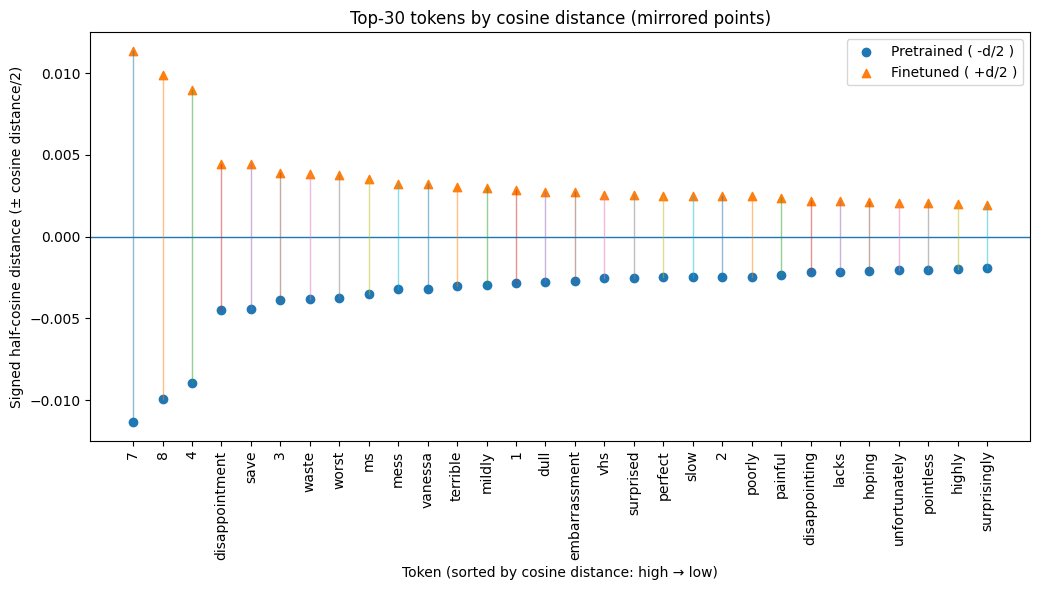

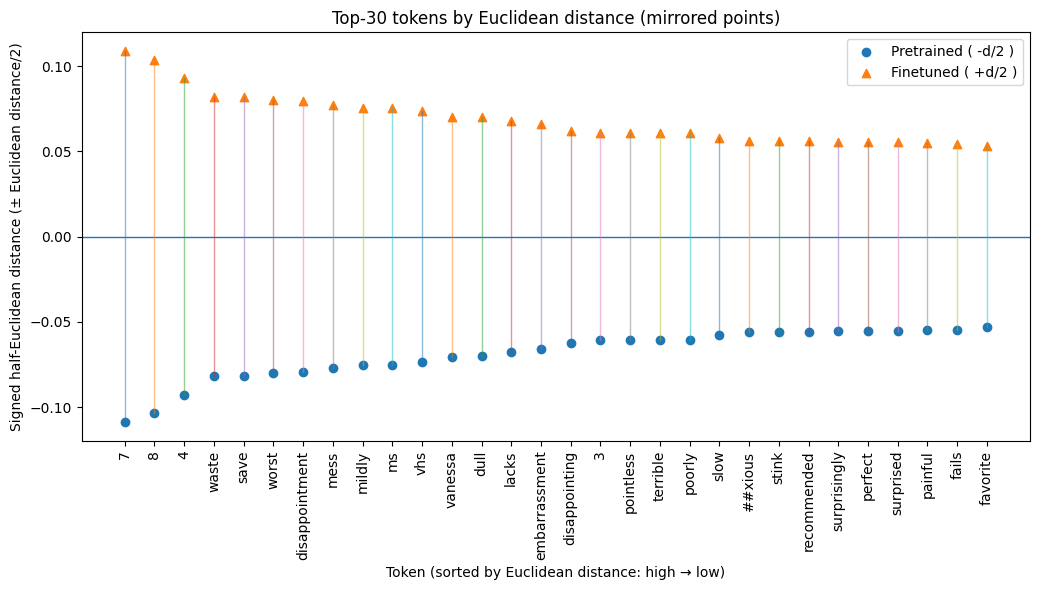

In [15]:
# Extract token IDs
token_ids_pretrained, tokens_pretrained, embeddings_pretrained = extract_token_ids_and_tokens(top_token_cluster_agg,emb_table_pretrained)
token_ids_finetuned, tokens_finetuned, embeddings_finetuned = extract_token_ids_and_tokens(top_token_cluster_agg,emb_table_finetuned)

# Pre Trained Bert
# Normalize embeddings
E_norm_pretrained = embeddings_pretrained / (np.linalg.norm(embeddings_pretrained, axis=1, keepdims=True) + 1e-12)
k = 3
kmeans_pretrained = KMeans(n_clusters=k, random_state=0, n_init="auto")
token_clusters_pretrained = kmeans_pretrained.fit_predict(E_norm_pretrained)

# Finetuned Bert
# Normalize embeddings
E_norm_finetuned = embeddings_finetuned / (np.linalg.norm(embeddings_finetuned, axis=1, keepdims=True) + 1e-12)
k = 3
kmeans_finetuned = KMeans(n_clusters=k, random_state=0, n_init="auto")
token_clusters_finetuned = kmeans_finetuned.fit_predict(E_norm_finetuned)
results = analyze_and_plot_three_metrics(
    token_ids_pretrained=token_ids_pretrained,
    tokens_pretrained=tokens_pretrained,
    embeddings_pretrained=embeddings_pretrained,
    token_ids_finetuned=token_ids_finetuned,
    tokens_finetuned=tokens_finetuned,
    embeddings_finetuned=embeddings_finetuned,
    top_n=30,
)

In [16]:
def pca_2d_scores(pre_emb, fin_emb):
    """
    Fit a 2D PCA projection on combined embeddings.
    """
    pre_emb = np.asarray(pre_emb, dtype=np.float64)
    fin_emb = np.asarray(fin_emb, dtype=np.float64)

    X = np.vstack([pre_emb, fin_emb])
    mu = X.mean(axis=0, keepdims=True)
    Xc = X - mu
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    W = Vt[:2].T   # [D, 2]

    pre_2d = (pre_emb - mu) @ W
    fin_2d = (fin_emb - mu) @ W
    return pre_2d, fin_2d

def plot_token_pairs_pca2(
    tokens,
    pre_emb,
    fin_emb,
    top_n=40,
    title=None,
):
    """
    Plot pretrained and finetuned token embeddings in a shared 2D PCA space,
    with a line connecting each token pair.
    Top_n tokens are selected by Euclidean shift in original space.
    """
    pre_emb = np.asarray(pre_emb, dtype=np.float64)
    fin_emb = np.asarray(fin_emb, dtype=np.float64)

    shift = np.linalg.norm(fin_emb - pre_emb, axis=1)
    order = np.argsort(shift)[::-1]
    order = order[: min(top_n, len(order))]

    tokens_plot = [tokens[i] for i in order]
    pre_2d, fin_2d = pca_2d_scores(pre_emb[order], fin_emb[order])

    plt.figure(figsize=(10, 8))

    for tok, p, f in zip(tokens_plot, pre_2d, fin_2d):
        plt.plot([p[0], f[0]], [p[1], f[1]], linewidth=1, alpha=0.7)
        plt.text(f[0], f[1], tok, fontsize=15)

    plt.scatter(pre_2d[:, 0], pre_2d[:, 1], marker="o", label="Pretrained")
    plt.scatter(fin_2d[:, 0], fin_2d[:, 1], marker="^", label="Finetuned")

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(title or "Pretrained vs finetuned token embeddings (2D PCA)")
    plt.legend()
    plt.tight_layout()
    plt.show()

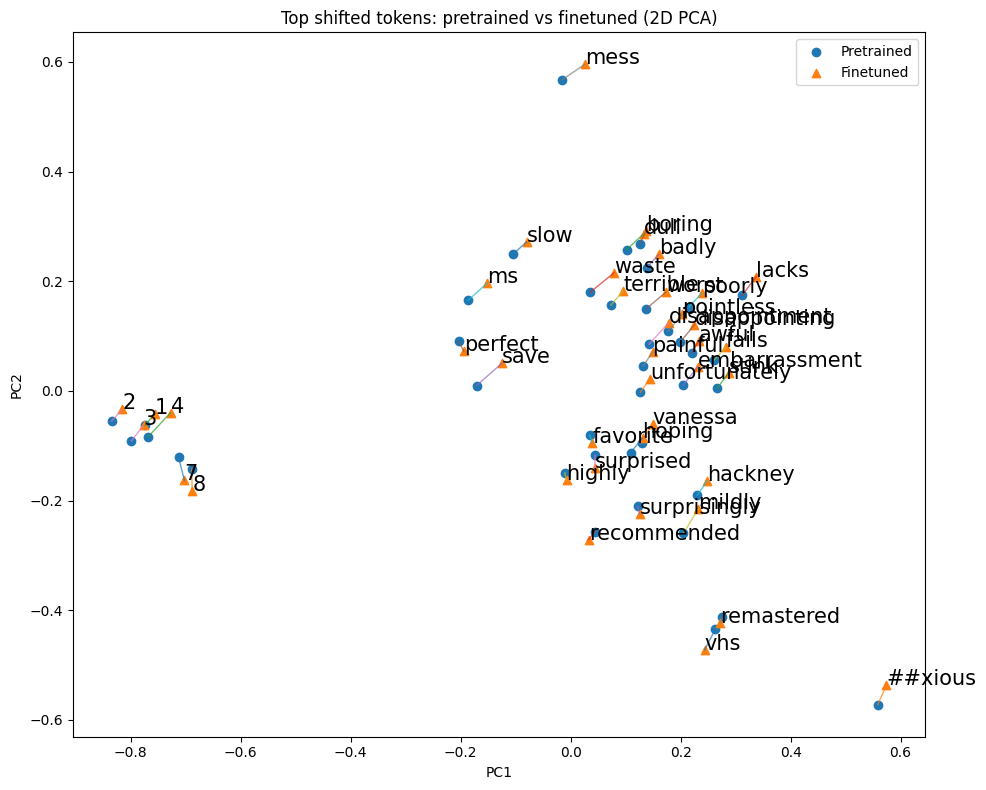

In [17]:
ids, toks, pre_emb, fin_emb = align_by_token_id(
    token_ids_pretrained, tokens_pretrained, embeddings_pretrained,
    token_ids_finetuned, tokens_finetuned, embeddings_finetuned
)
plot_token_pairs_pca2(
    tokens=toks,
    pre_emb=pre_emb,
    fin_emb=fin_emb,
    top_n=40,
    title="Top shifted tokens: pretrained vs finetuned (2D PCA)"
)

2. top_tokens_per_cluster_max

/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/2087324147.py:7: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_pretrained = embeddings_pretrained / (np.linalg.norm(embeddings_pretrained, axis=1, keepdims=True) + 1e-12)
/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/2087324147.py:14: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_finetuned = embeddings_finetuned / (np.linalg.norm(embeddings_finetuned, axis=1, keepdims=True) + 1e-12)


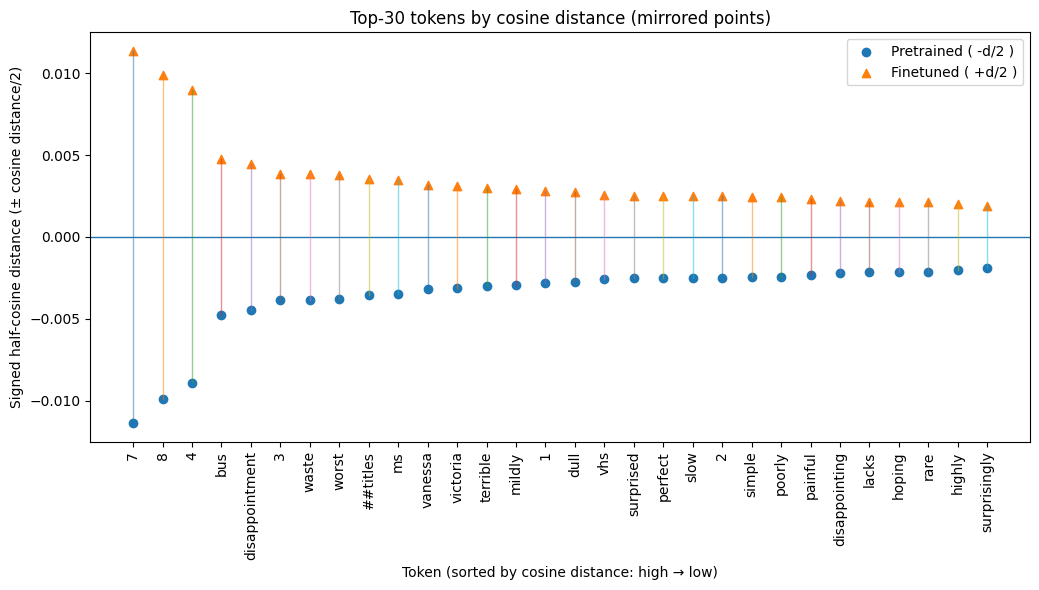

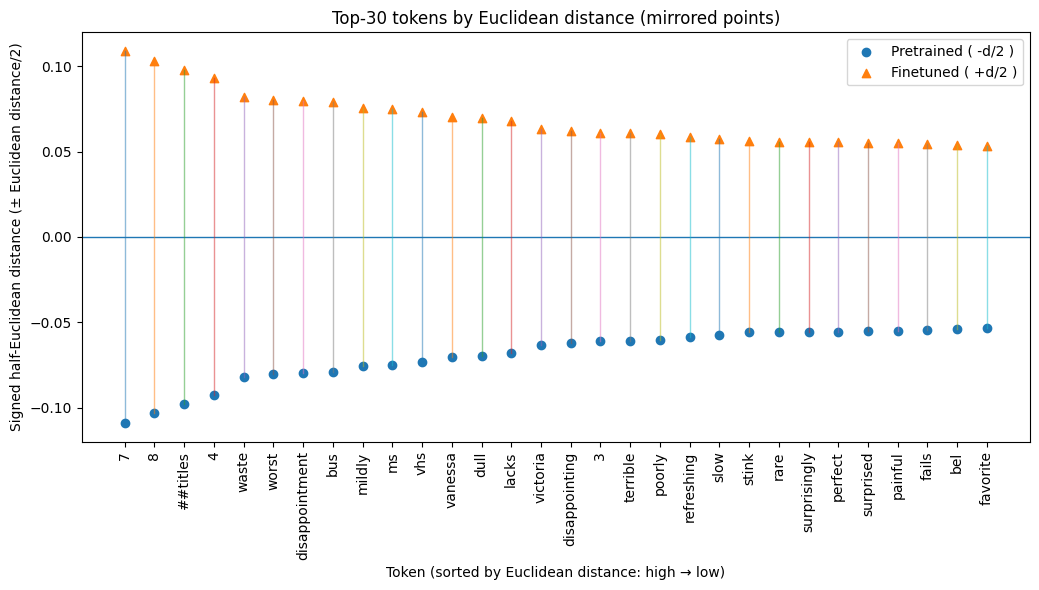

In [18]:
# Extract all tokens and embeddings
token_ids_pretrained, tokens_pretrained, embeddings_pretrained = extract_token_ids_and_tokens(top_tokens_per_cluster_max,emb_table_pretrained)
token_ids_finetuned, tokens_finetuned, embeddings_finetuned = extract_token_ids_and_tokens(top_tokens_per_cluster_max,emb_table_finetuned)

# Pre Trained Bert
# Normalize embeddings
E_norm_pretrained = embeddings_pretrained / (np.linalg.norm(embeddings_pretrained, axis=1, keepdims=True) + 1e-12)
k = 3
kmeans_pretrained = KMeans(n_clusters=k, random_state=0, n_init="auto")
token_clusters_pretrained = kmeans_pretrained.fit_predict(E_norm_pretrained)

# Finetuned Bert
# Normalize embeddings
E_norm_finetuned = embeddings_finetuned / (np.linalg.norm(embeddings_finetuned, axis=1, keepdims=True) + 1e-12)
k = 3
kmeans_finetuned = KMeans(n_clusters=k, random_state=0, n_init="auto")
token_clusters_finetuned = kmeans_finetuned.fit_predict(E_norm_finetuned)
results = analyze_and_plot_three_metrics(
    token_ids_pretrained=token_ids_pretrained,
    tokens_pretrained=tokens_pretrained,
    embeddings_pretrained=embeddings_pretrained,
    token_ids_finetuned=token_ids_finetuned,
    tokens_finetuned=tokens_finetuned,
    embeddings_finetuned=embeddings_finetuned,
    top_n=30,
)

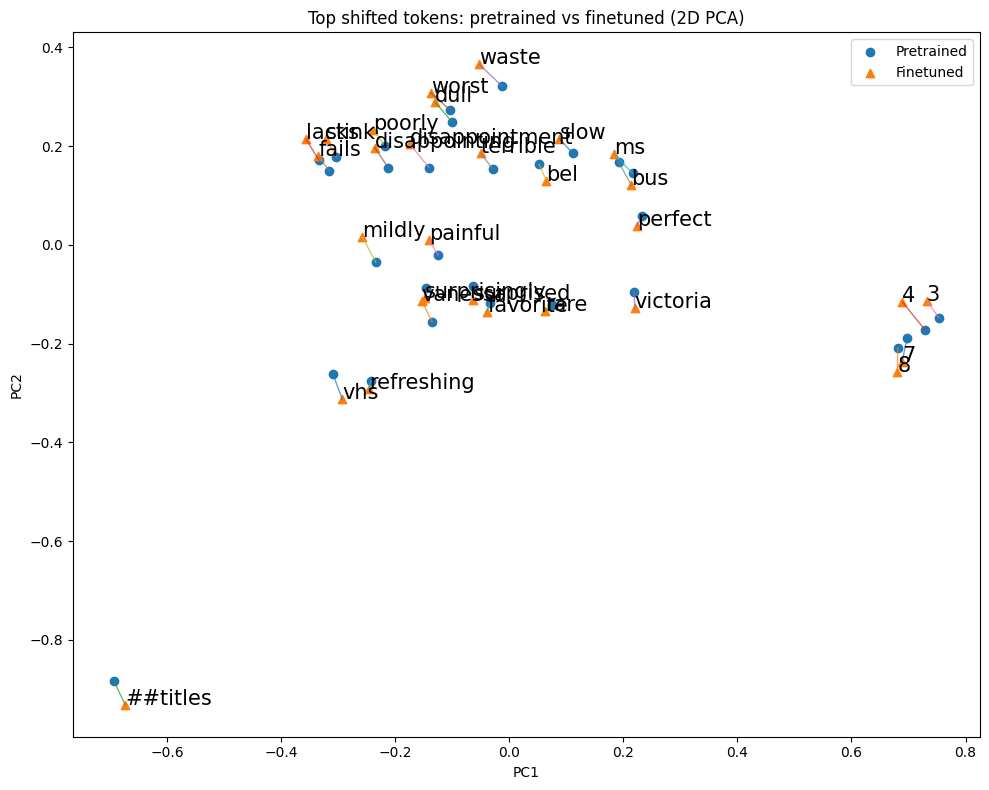

In [19]:
ids, toks, pre_emb, fin_emb = align_by_token_id(
    token_ids_pretrained, tokens_pretrained, embeddings_pretrained,
    token_ids_finetuned, tokens_finetuned, embeddings_finetuned
)
plot_token_pairs_pca2(
    tokens=toks,
    pre_emb=pre_emb,
    fin_emb=fin_emb,
    top_n=30,
    title="Top shifted tokens: pretrained vs finetuned (2D PCA)"
)

3. top_token_global_agg

/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/2823531949.py:7: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_pretrained = embeddings_pretrained / (np.linalg.norm(embeddings_pretrained, axis=1, keepdims=True) + 1e-12)
/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/2823531949.py:14: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_finetuned = embeddings_finetuned / (np.linalg.norm(embeddings_finetuned, axis=1, keepdims=True) + 1e-12)


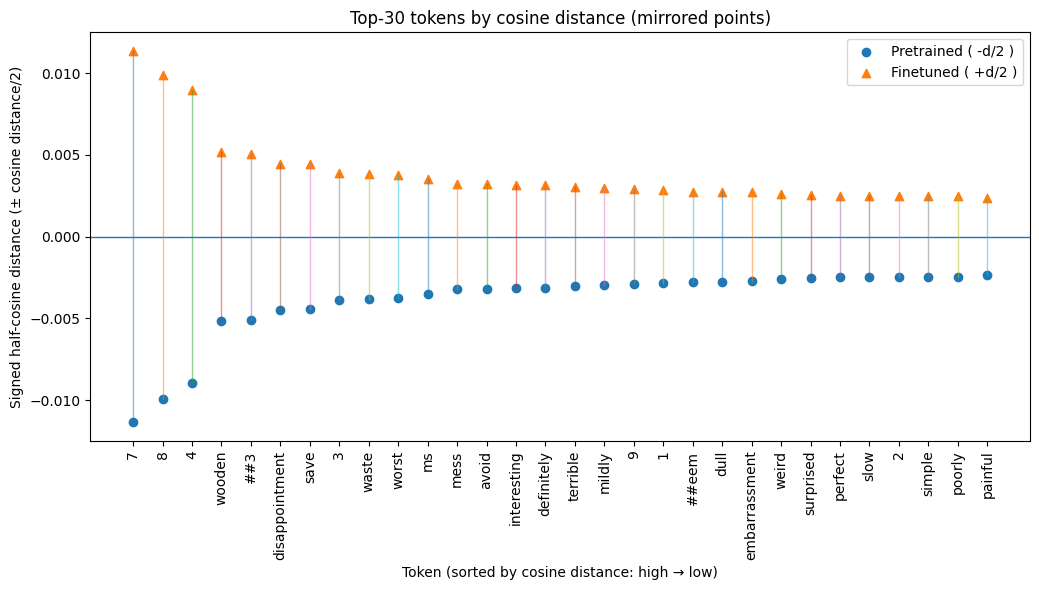

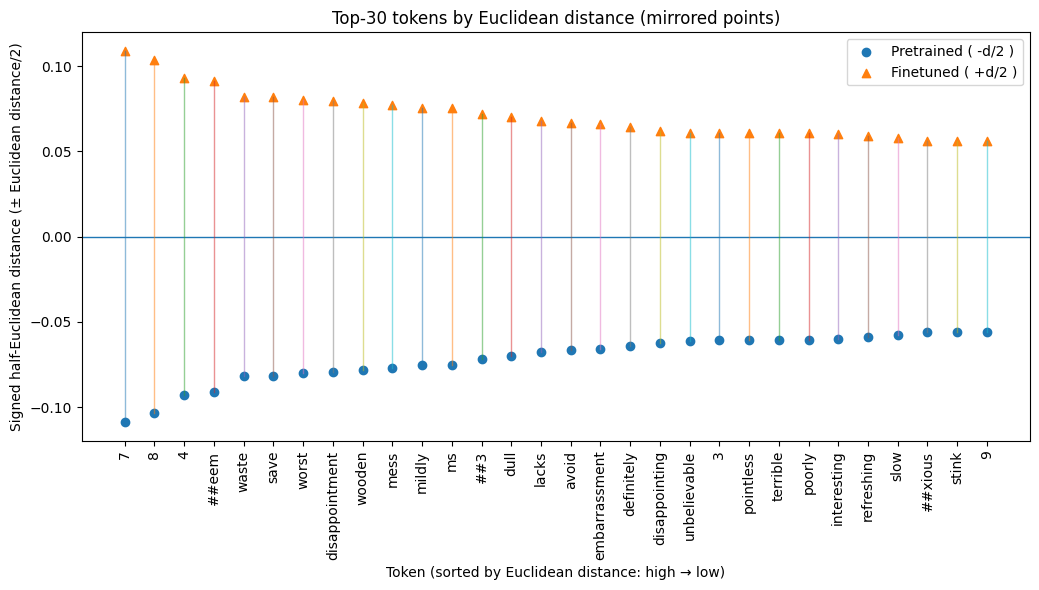

In [20]:
# Extract all tokens and embeddings
token_ids_pretrained, tokens_pretrained, embeddings_pretrained = extract_token_ids_and_tokens(top_token_global_agg,emb_table_pretrained)
token_ids_finetuned, tokens_finetuned, embeddings_finetuned = extract_token_ids_and_tokens(top_token_global_agg,emb_table_finetuned)

# Pre Trained Bert
# Normalize embeddings
E_norm_pretrained = embeddings_pretrained / (np.linalg.norm(embeddings_pretrained, axis=1, keepdims=True) + 1e-12)
k = 3
kmeans_pretrained = KMeans(n_clusters=k, random_state=0, n_init="auto")
token_clusters_pretrained = kmeans_pretrained.fit_predict(E_norm_pretrained)

# Finetuned Bert
# Normalize embeddings
E_norm_finetuned = embeddings_finetuned / (np.linalg.norm(embeddings_finetuned, axis=1, keepdims=True) + 1e-12)
k = 3
kmeans_finetuned = KMeans(n_clusters=k, random_state=0, n_init="auto")
token_clusters_finetuned = kmeans_finetuned.fit_predict(E_norm_finetuned)
results = analyze_and_plot_three_metrics(
    token_ids_pretrained=token_ids_pretrained,
    tokens_pretrained=tokens_pretrained,
    embeddings_pretrained=embeddings_pretrained,
    token_ids_finetuned=token_ids_finetuned,
    tokens_finetuned=tokens_finetuned,
    embeddings_finetuned=embeddings_finetuned,
    top_n=30,
)

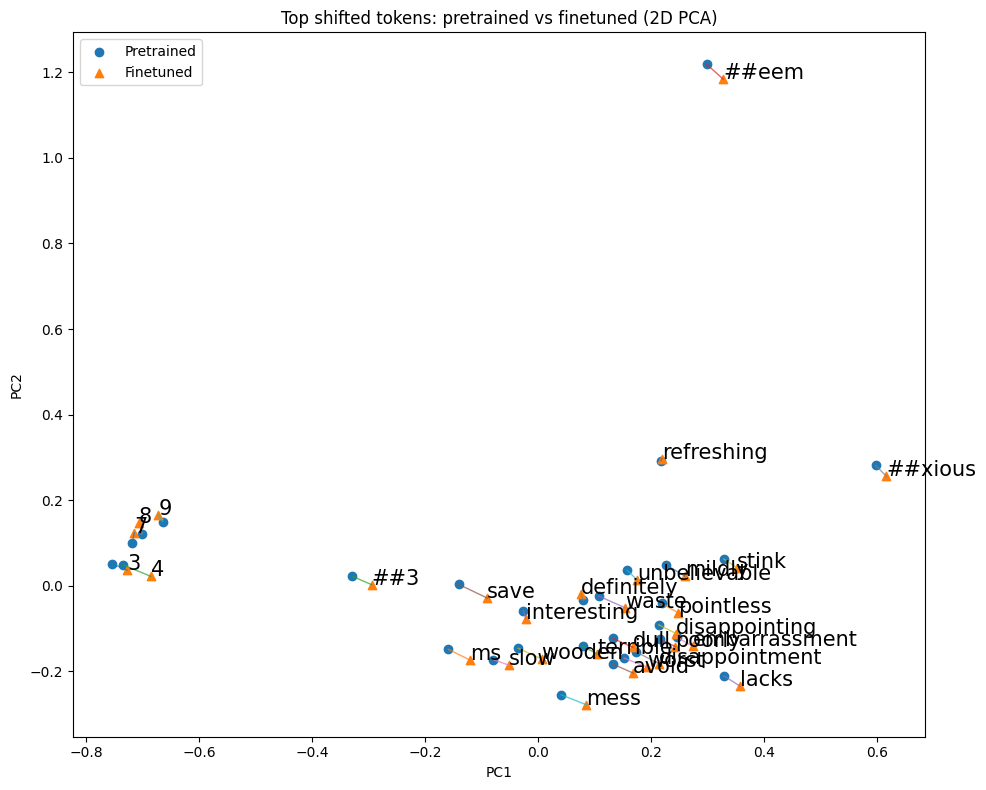

In [21]:
ids, toks, pre_emb, fin_emb = align_by_token_id(
    token_ids_pretrained, tokens_pretrained, embeddings_pretrained,
    token_ids_finetuned, tokens_finetuned, embeddings_finetuned
)
plot_token_pairs_pca2(
    tokens=toks,
    pre_emb=pre_emb,
    fin_emb=fin_emb,
    top_n=30,
    title="Top shifted tokens: pretrained vs finetuned (2D PCA)"
)

4. top_tokens_global_max

/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/1081823053.py:7: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_pretrained = embeddings_pretrained / (np.linalg.norm(embeddings_pretrained, axis=1, keepdims=True) + 1e-12)
/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/1081823053.py:14: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_finetuned = embeddings_finetuned / (np.linalg.norm(embeddings_finetuned, axis=1, keepdims=True) + 1e-12)


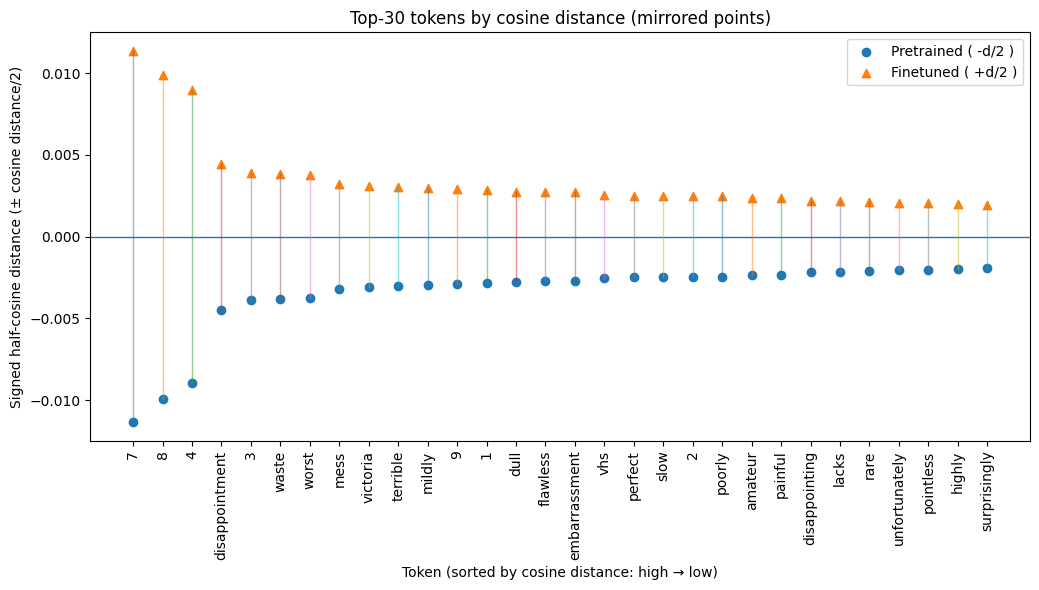

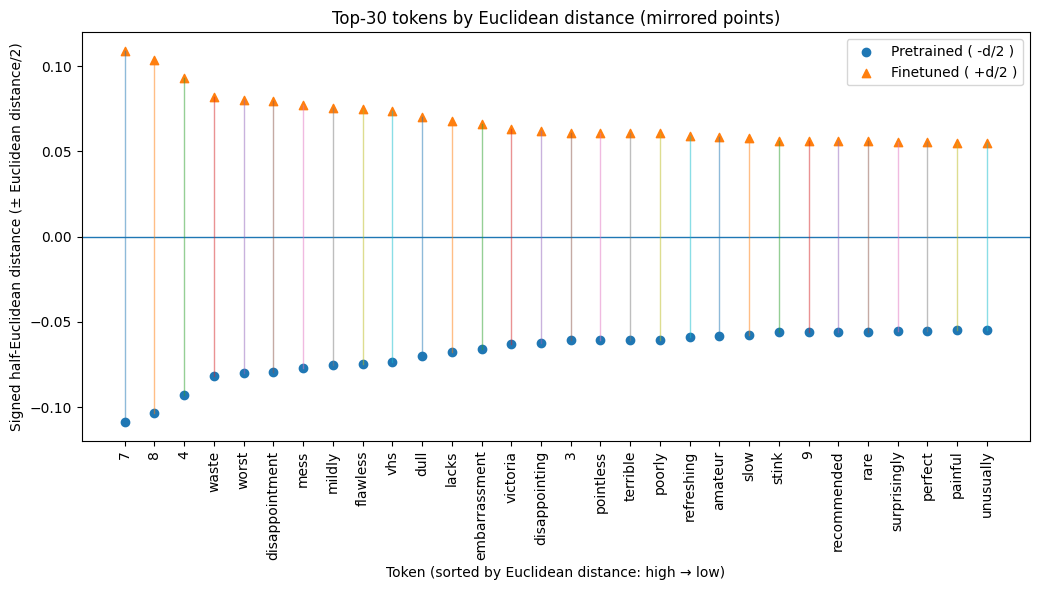

In [22]:
#Extract all tokens and embeddings
token_ids_pretrained, tokens_pretrained, embeddings_pretrained = extract_token_ids_and_tokens(top_token_global_max,emb_table_pretrained)
token_ids_finetuned, tokens_finetuned, embeddings_finetuned = extract_token_ids_and_tokens(top_token_global_max,emb_table_finetuned)

# Pre Trained Bert
# Normalize embeddings
E_norm_pretrained = embeddings_pretrained / (np.linalg.norm(embeddings_pretrained, axis=1, keepdims=True) + 1e-12)
k = 3
kmeans_pretrained = KMeans(n_clusters=k, random_state=0, n_init="auto")
token_clusters_pretrained = kmeans_pretrained.fit_predict(E_norm_pretrained)

# Finetuned Bert
# Normalize embeddings
E_norm_finetuned = embeddings_finetuned / (np.linalg.norm(embeddings_finetuned, axis=1, keepdims=True) + 1e-12)
k = 3
kmeans_finetuned = KMeans(n_clusters=k, random_state=0, n_init="auto")
token_clusters_finetuned = kmeans_finetuned.fit_predict(E_norm_finetuned)
results = analyze_and_plot_three_metrics(
    token_ids_pretrained=token_ids_pretrained,
    tokens_pretrained=tokens_pretrained,
    embeddings_pretrained=embeddings_pretrained,
    token_ids_finetuned=token_ids_finetuned,
    tokens_finetuned=tokens_finetuned,
    embeddings_finetuned=embeddings_finetuned,
    top_n=30,
)


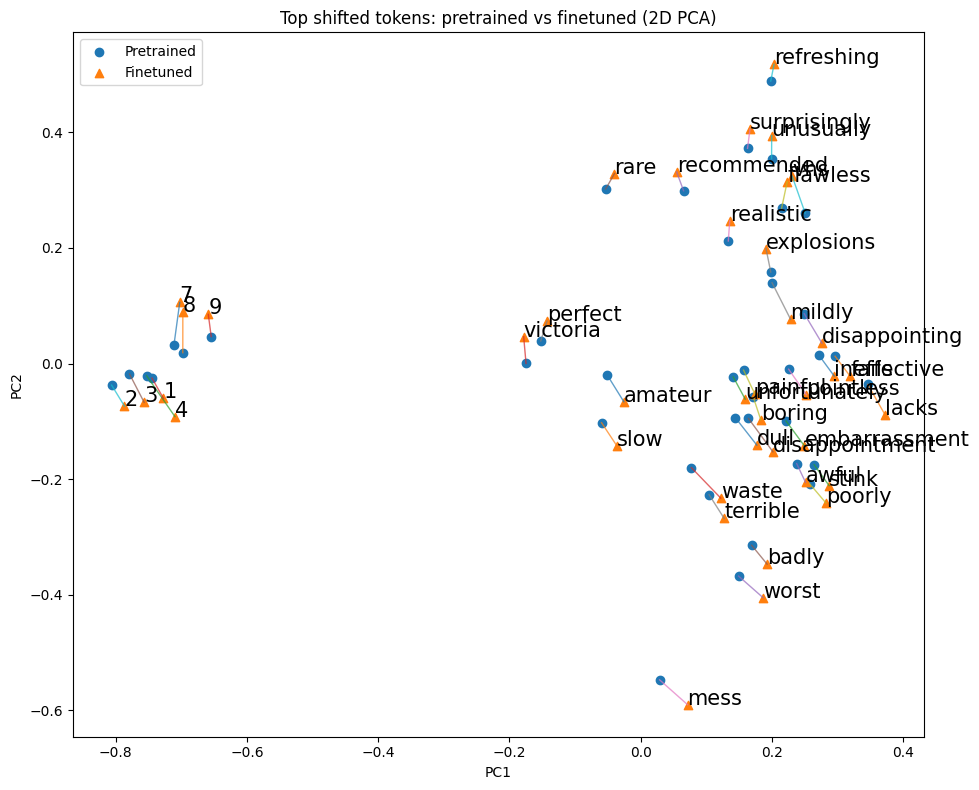

In [23]:
ids, toks, pre_emb, fin_emb = align_by_token_id(
    token_ids_pretrained, tokens_pretrained, embeddings_pretrained,
    token_ids_finetuned, tokens_finetuned, embeddings_finetuned
)
plot_token_pairs_pca2(
    tokens=toks,
    pre_emb=pre_emb,
    fin_emb=fin_emb,
    top_n=40,
    title="Top shifted tokens: pretrained vs finetuned (2D PCA)"
)

In [87]:

def plot_token_pairs_pca2_2(
    tokens,
    pre_emb,
    fin_emb,
    top_n=40,
    top_k=15,
    title=None,
):
    """
    Fit PCA using the top_n tokens ranked by Euclidean embedding shift.
    Display only the top_k tokens in the resulting shared PCA space.
    """
    pre_emb = np.asarray(pre_emb, dtype=np.float64)
    fin_emb = np.asarray(fin_emb, dtype=np.float64)

    if not 1 <= top_k <= top_n:
        raise ValueError("top_k must be between 1 and top_n")

    shift = np.linalg.norm(fin_emb - pre_emb, axis=1)
    order = np.argsort(shift)[::-1]
    order = order[:min(top_n, len(order))]

    # PCA uses top_n tokens
    pre_2d, fin_2d = pca_2d_scores(
        pre_emb[order],
        fin_emb[order]
    )

    # Display only top_k tokens
    k = min(top_k, len(order))
    tokens_plot = [tokens[i] for i in order[:k]]
    pre_plot = pre_2d[:k]
    fin_plot = fin_2d[:k]

    plt.figure(figsize=(10, 8))

    for tok, p, f in zip(tokens_plot, pre_plot, fin_plot):
        plt.plot(
            [p[0], f[0]],
            [p[1], f[1]],
            linewidth=1,
            alpha=0.7
        )
        plt.text(f[0], f[1], tok, fontsize=15)

    plt.scatter(
        pre_plot[:, 0], pre_plot[:, 1],
        marker="o", label="Pretrained"
    )
    plt.scatter(
        fin_plot[:, 0], fin_plot[:, 1],
        marker="^", label="Finetuned"
    )

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    # plt.title(title or "Pretrained vs finetuned token embeddings (2D PCA)")
    plt.legend()
    ax = plt.gca()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()
    plt.show()


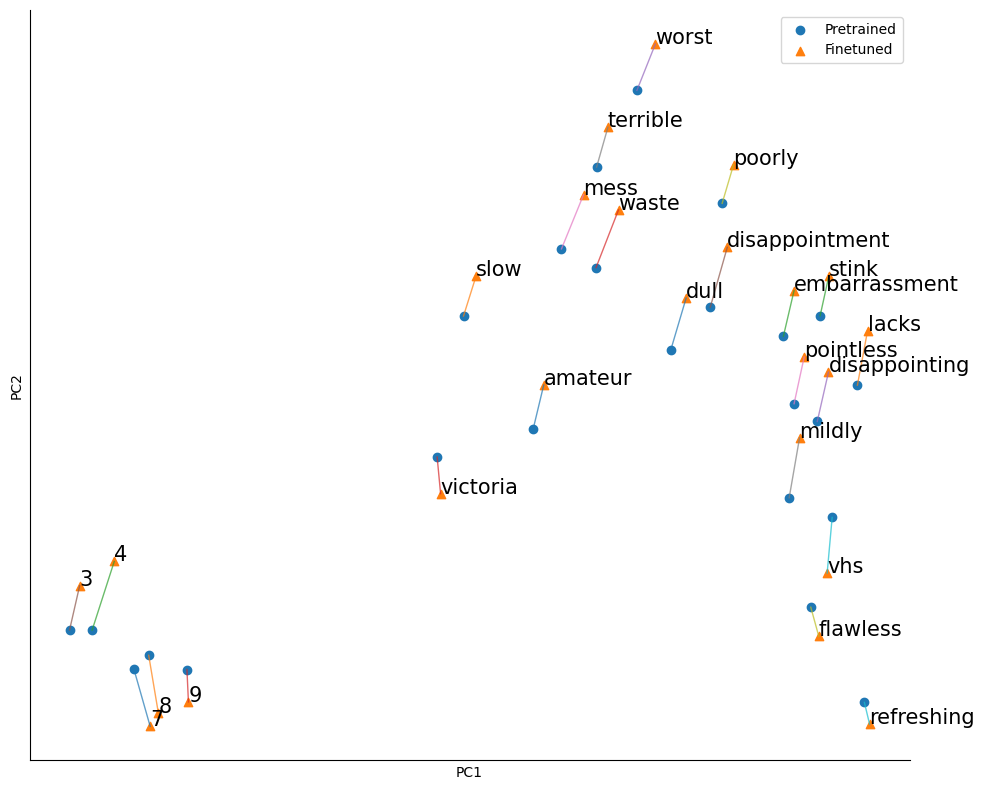

In [88]:
plot_token_pairs_pca2_2(
    toks,
    pre_emb,
    fin_emb,
    top_n=100,
    top_k=24
)

---

Obersvation: 
1. Biggest Cosine/ Euclidean shift is with the tokens 7,8 and 4 which seems to strengthen the argument that numerical tokens experience a strong shift through Finetuning BERT on the IMDB Dataset, even though we are at the very first layer of the model.
2. Numeric/tokenization-driven items cluster together in a separate region, distinct from the main lexical sentiment-bearing tokens. In the clusterwise views, several positive/evaluative words appear to move in a similar upward direction in the 2D PCA projection, whereas several negative cues shift in a different, partially opposing direction, indicating semantically structured embedding drift after fine-tuning. Among the four extraction methods, the global aggregated token set appears to exhibit the smallest overall change.

---

Positive Subset

In [24]:
def top_tokens_per_cluster_agg(R_vocab, cluster_ids, tokenizer, top_n=20, exclude_special=False):
    """
    Return the top top_n tokens per cluster by summed saliency (columns).

    For each cluster, saliency scores are summed across all assigned examples
    and the highest scoring tokens are returned as
    (token_id, token_string, score) tuples.
    """

    n_clusters = int(cluster_ids.max()) + 1
    results = {}
    
    # removing: [UNK][SEP][PAD][CLS][MASK]
    special_ids = set(tokenizer.all_special_ids) if exclude_special else set()

    # iterate clusters
    for c in range(n_clusters):
        idx = np.where(cluster_ids == c)[0]
        if len(idx) == 0:
            results[c] = []
            continue

        # Aggregate saliency over columns
        agg = R_vocab[idx].sum(axis=0)  # shape: (vocab_size,)
        agg = np.asarray(agg).reshape(-1)

        # zero out special tokens
        if exclude_special:
            agg[list(special_ids)] = 0.0

        top_ids = np.argsort(-agg)[:top_n]
        top_scores = agg[top_ids]
        top_toks = tokenizer.convert_ids_to_tokens(top_ids.tolist())

        results[c] = list(zip(top_ids.tolist(), top_toks, top_scores.tolist()))
    return results

def top_tokens_per_cluster_max(R_vocab, cluster_ids, tokenizer, top_n=20, exclude_special=False):
    """
    Return the top top_n tokens per cluster by maximum saliency( over columns).

    For each cluster, this takes the maximum saliency value for each token
    across all assigned examples and returns the highest-scoring tokens as
    (token_id, token_string, score) tuples.
    """

    n_clusters = int(cluster_ids.max()) + 1
    results = {}

    special_ids = set(tokenizer.all_special_ids) if exclude_special else set()

    # helper: robust row-subset max for dense or sparse
    def _colwise_max(mat):
        # scipy sparse matrices have .max(axis=0)
        if hasattr(mat, "tocoo"):  # crude but effective sparse check
            m = mat.max(axis=0)              # 1 x V
            return np.asarray(m).reshape(-1) # -> (V,)
        else:
            return np.max(mat, axis=0)

    for c in range(n_clusters):
        idx = np.where(cluster_ids == c)[0]
        if len(idx) == 0:
            results[c] = []
            continue

        col_max = _colwise_max(R_vocab[idx])  # shape: (vocab_size,)

        if exclude_special:
            col_max[list(special_ids)] = 0.0

        top_ids = np.argsort(-col_max)[:top_n]
        top_scores = col_max[top_ids]
        top_toks = tokenizer.convert_ids_to_tokens(top_ids.tolist())

        results[c] = list(zip(top_ids.tolist(), top_toks, top_scores.tolist()))

    return results

def top_tokens_global_agg(R_vocab, tokenizer, top_n=50, exclude_special=False):
    """
    Return the top_n tokens by summed saliency over all examples.

    This sums saliency scores column-wise across R_vocab and returns the
    highest-scoring tokens as (token_id, token_string, score) tuples.
    """

    # Column-wise sum over all examples -> shape (vocab_size,)
    agg = R_vocab.sum(axis=0)

    # Ensure flat dense 1D array
    agg = np.asarray(agg).reshape(-1)

    if exclude_special:
        special_ids = tokenizer.all_special_ids
        agg[special_ids] = 0.0

    top_ids = np.argsort(-agg)[:top_n]
    top_scores = agg[top_ids]
    top_toks = tokenizer.convert_ids_to_tokens(top_ids.tolist())

    return list(zip(top_ids.tolist(), top_toks, top_scores.tolist()))


def top_tokens_global_max(R_vocab, tokenizer, top_n=50, exclude_special=False):
    """
    Return the top top_n tokens by maximum saliency over all examples.

    This takes the column-wise maximum over R_vocab and returns the
    highest-scoring tokens as (token_id, token_string, score) tuples.
    """
    
    # Column-wise max over all rows -> shape (vocab_size,)
    max_vals = R_vocab.max(axis=0)

    # Ensure a flat dense 1D array (handles sparse matrices / numpy matrices)
    max_vals = np.asarray(max_vals).reshape(-1)

    if exclude_special:
        special_ids = tokenizer.all_special_ids
        max_vals[special_ids] = 0.0

    top_ids = np.argsort(-max_vals)[:top_n]
    top_scores = max_vals[top_ids]
    top_toks = tokenizer.convert_ids_to_tokens(top_ids.tolist())

    return list(zip(top_ids.tolist(), top_toks, top_scores.tolist()))

In [25]:
# Select positively predicted examples and build saliency matrix
pos_indices = [i for i, p in enumerate(test_preds) if p == 1]

np.random.seed(42)
sample_size = min(2500, len(pos_indices))
pos_sample_indices = np.random.choice(pos_indices, size=sample_size, replace=False)

R_vocab_pos, texts_pos = build_salience_vocab_matrix_from_indices(
    test_data,
    pos_sample_indices,
    model,
    tokenizer,
    device,
    top_k=5,
)
cluster_ids_pos, kmeans_pos = cluster_salience(R_vocab_pos, n_clusters=5)


100%|██████████| 2500/2500 [02:28<00:00, 16.82it/s]


/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/3926429935.py:32: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_pretrained = embeddings_pretrained / (
/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/3926429935.py:38: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_finetuned = embeddings_finetuned / (


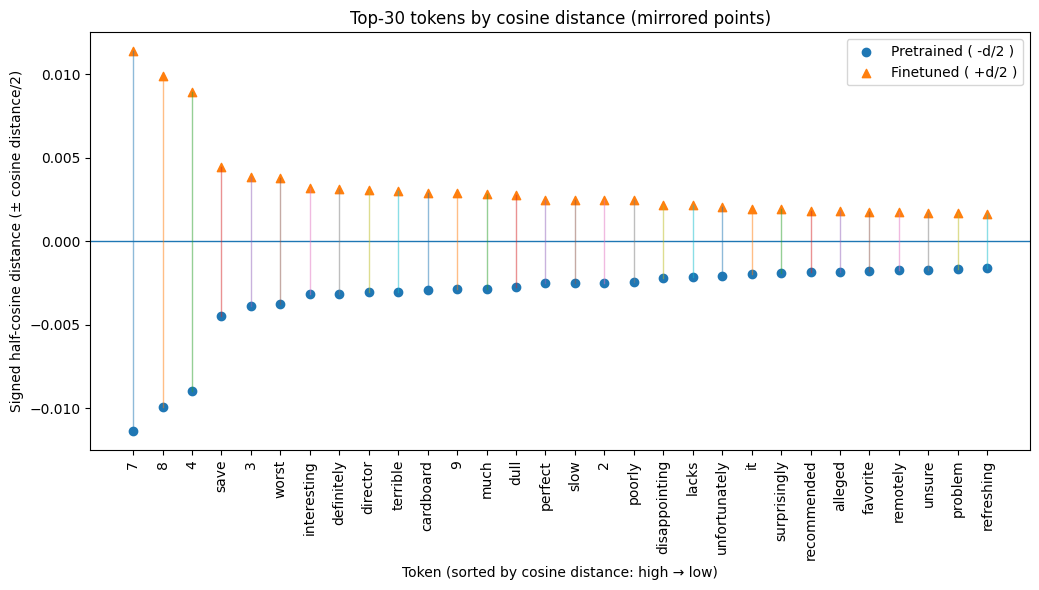

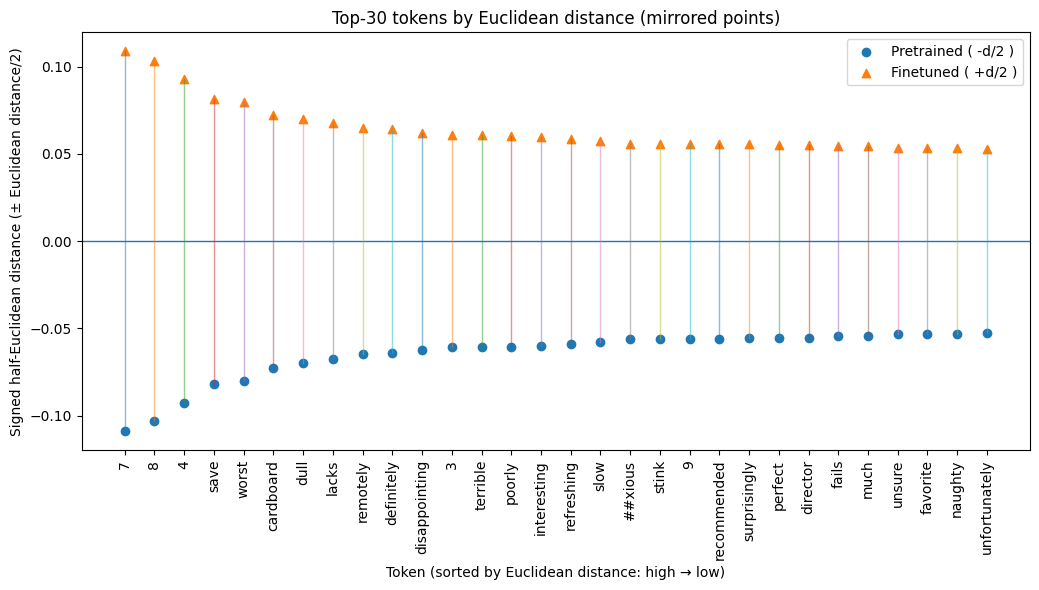

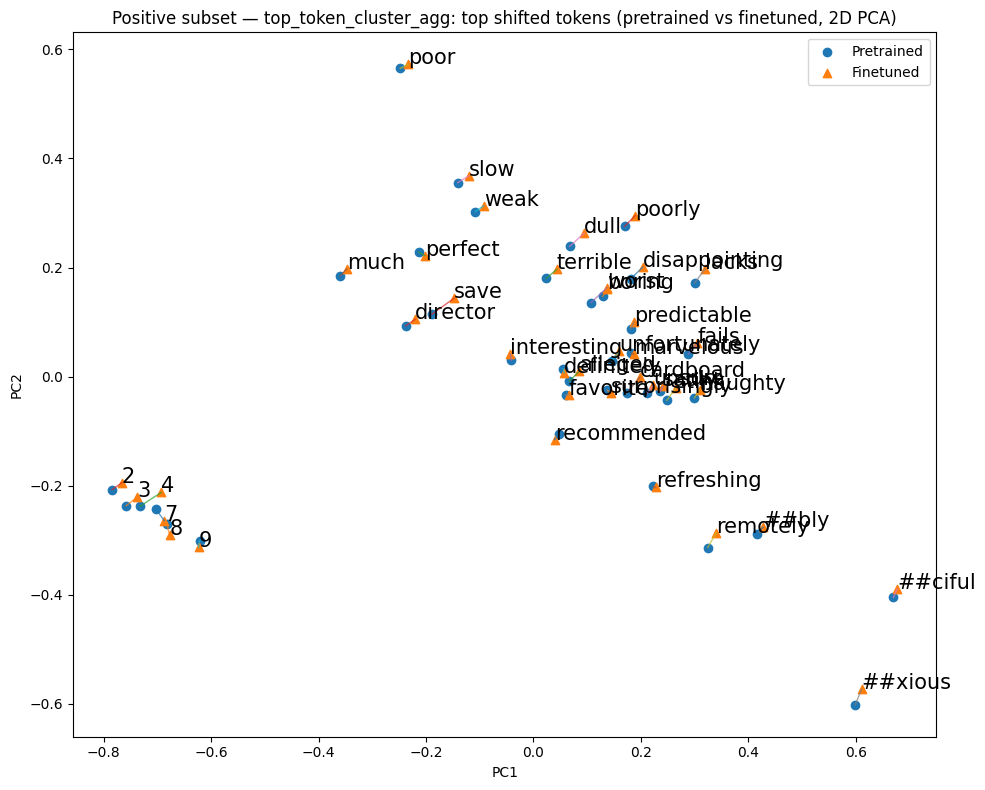

/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/3926429935.py:32: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_pretrained = embeddings_pretrained / (
/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/3926429935.py:38: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_finetuned = embeddings_finetuned / (


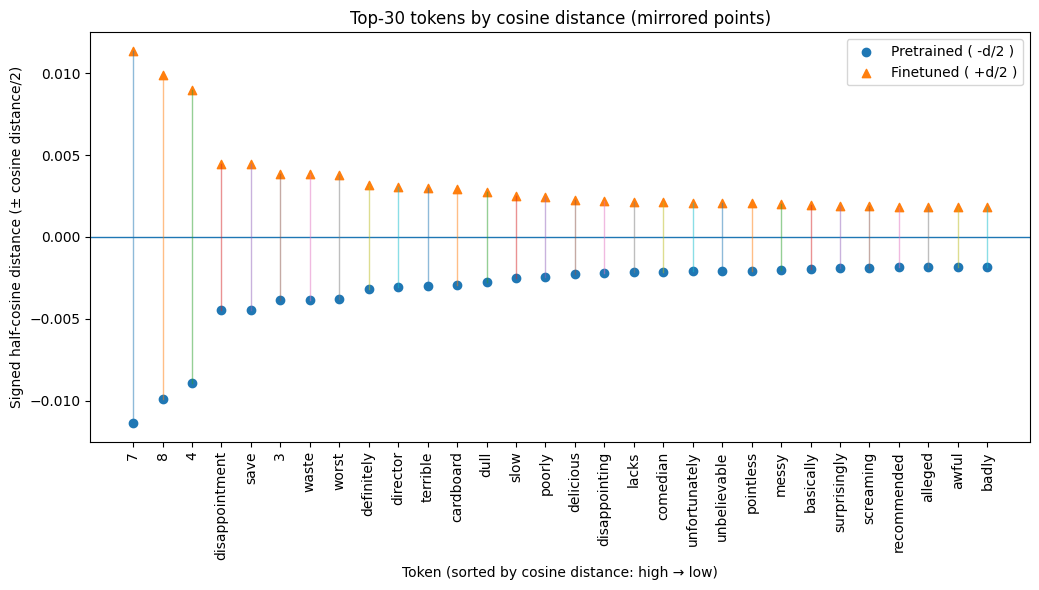

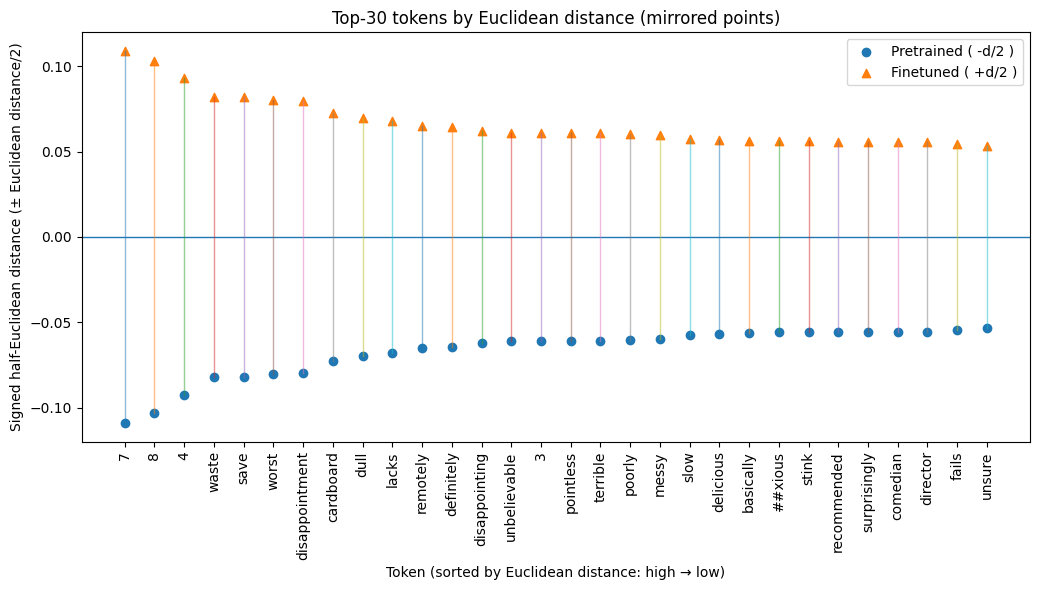

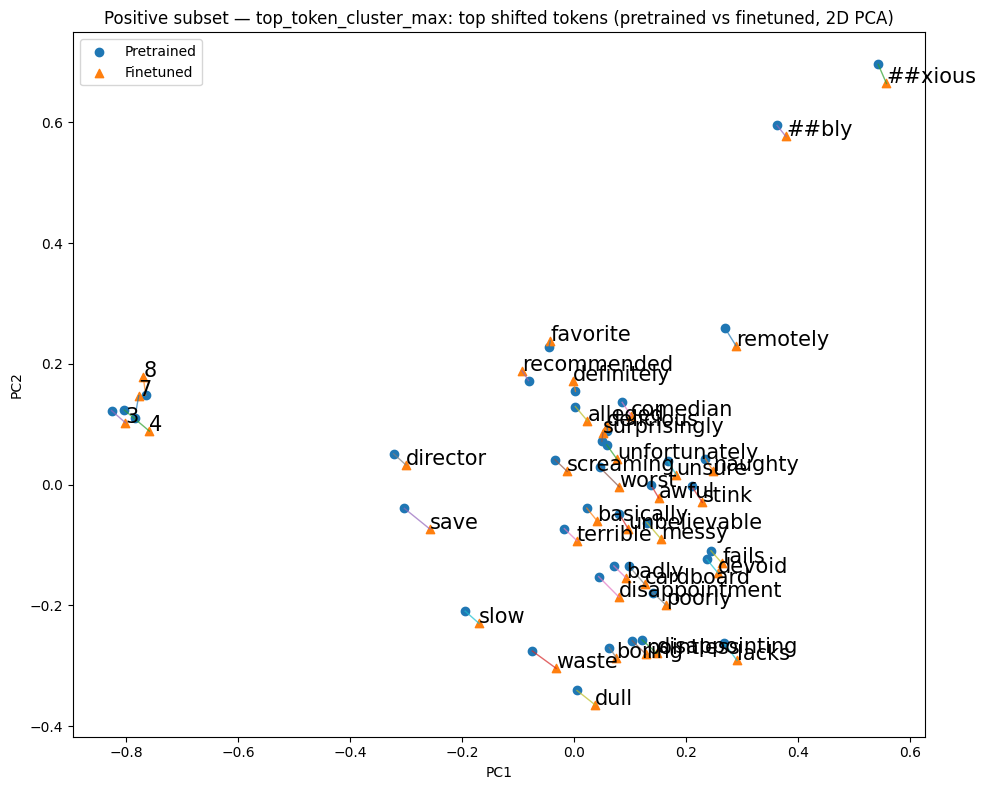

/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/3926429935.py:32: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_pretrained = embeddings_pretrained / (
/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/3926429935.py:38: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_finetuned = embeddings_finetuned / (


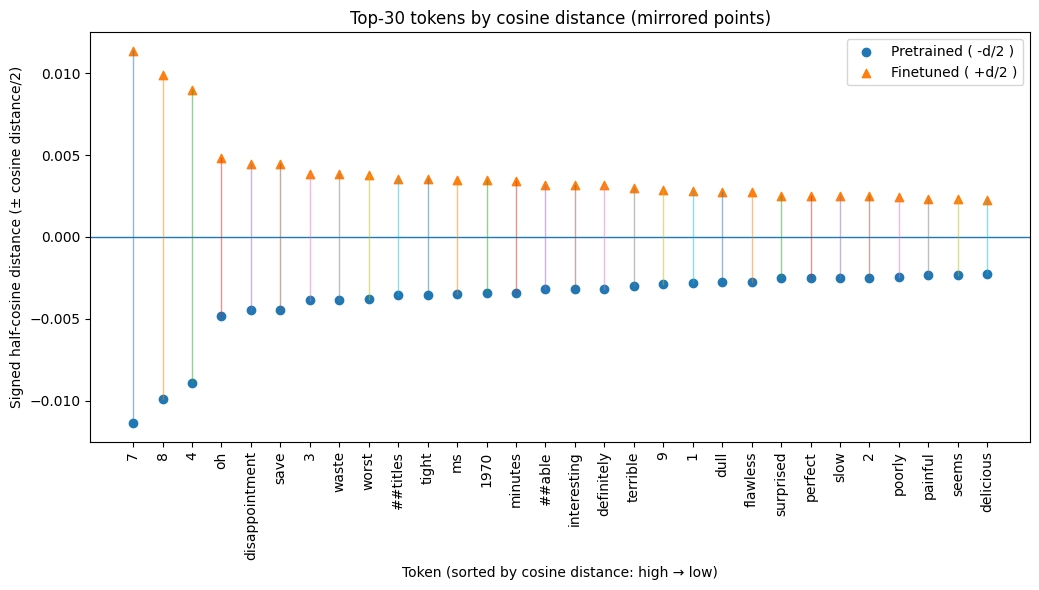

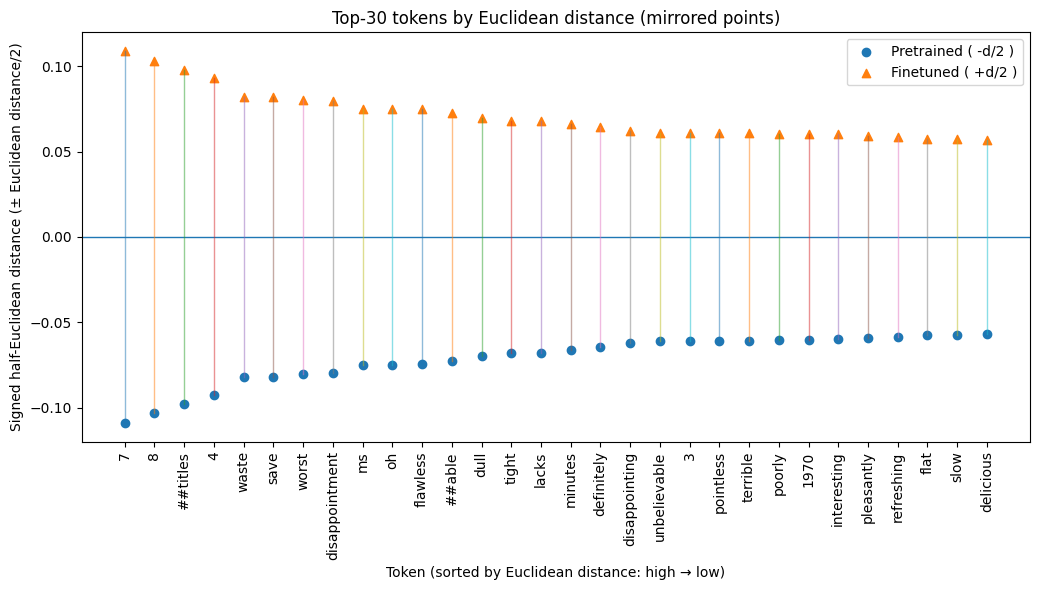

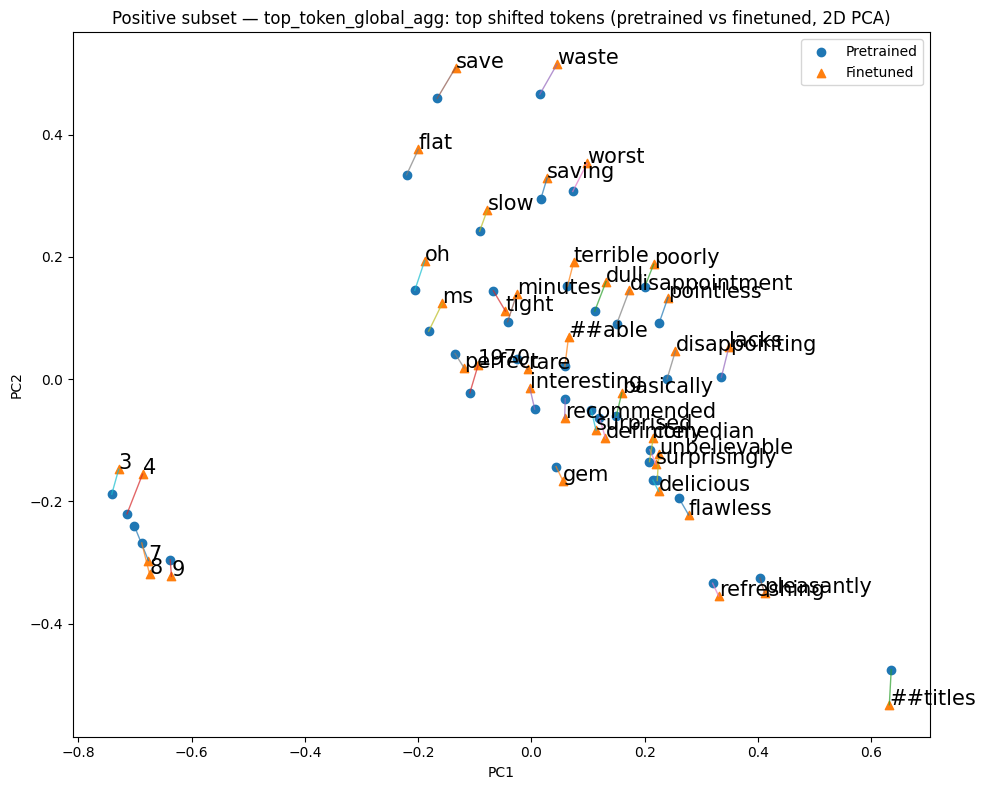

/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/3926429935.py:32: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_pretrained = embeddings_pretrained / (
/var/folders/l5/3zb8ns612s38jb5qz423_rvr0000gn/T/ipykernel_9387/3926429935.py:38: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  E_norm_finetuned = embeddings_finetuned / (


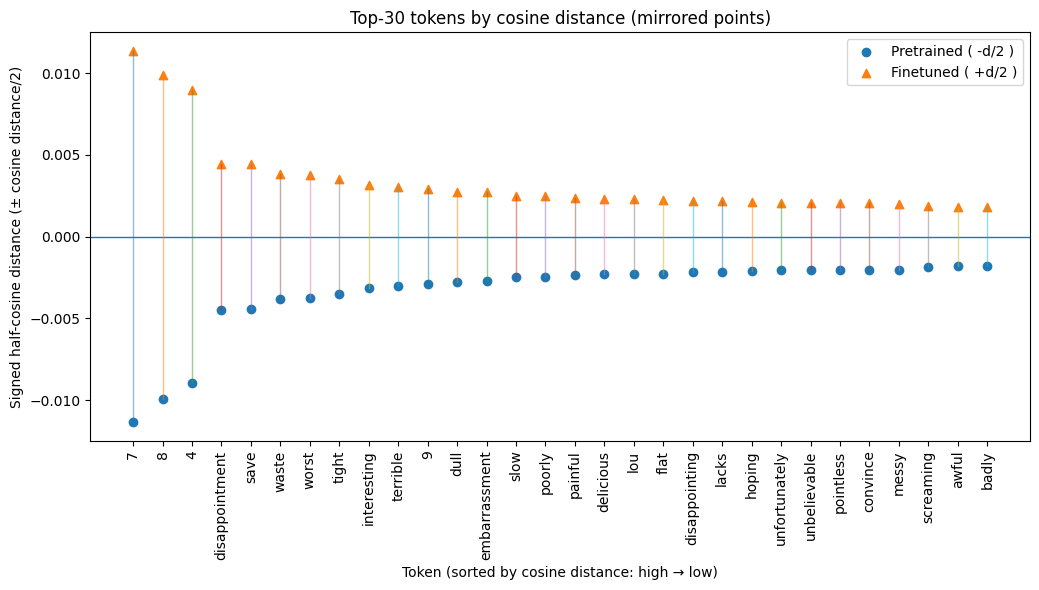

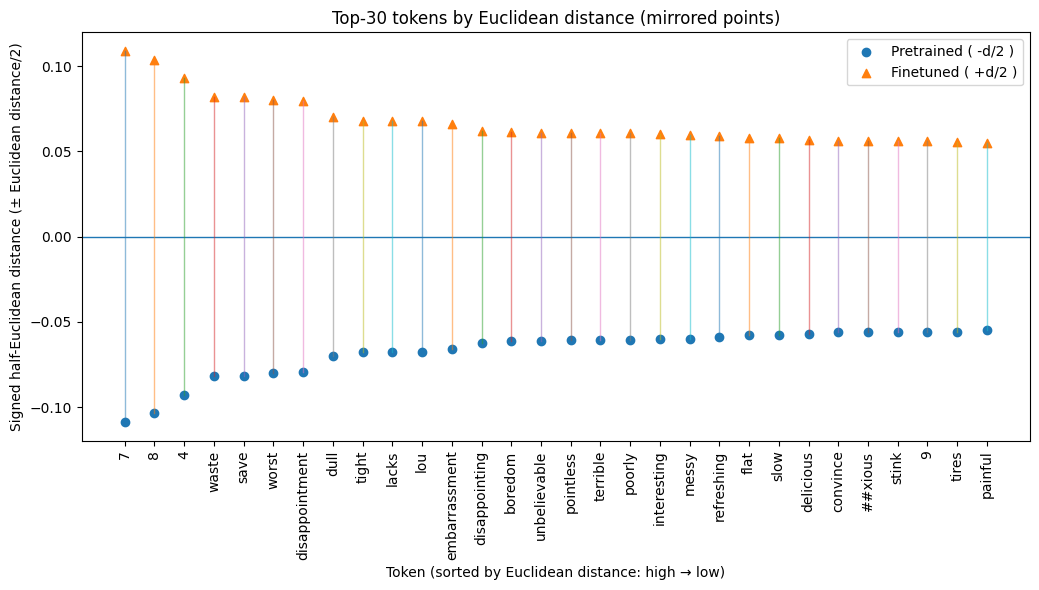

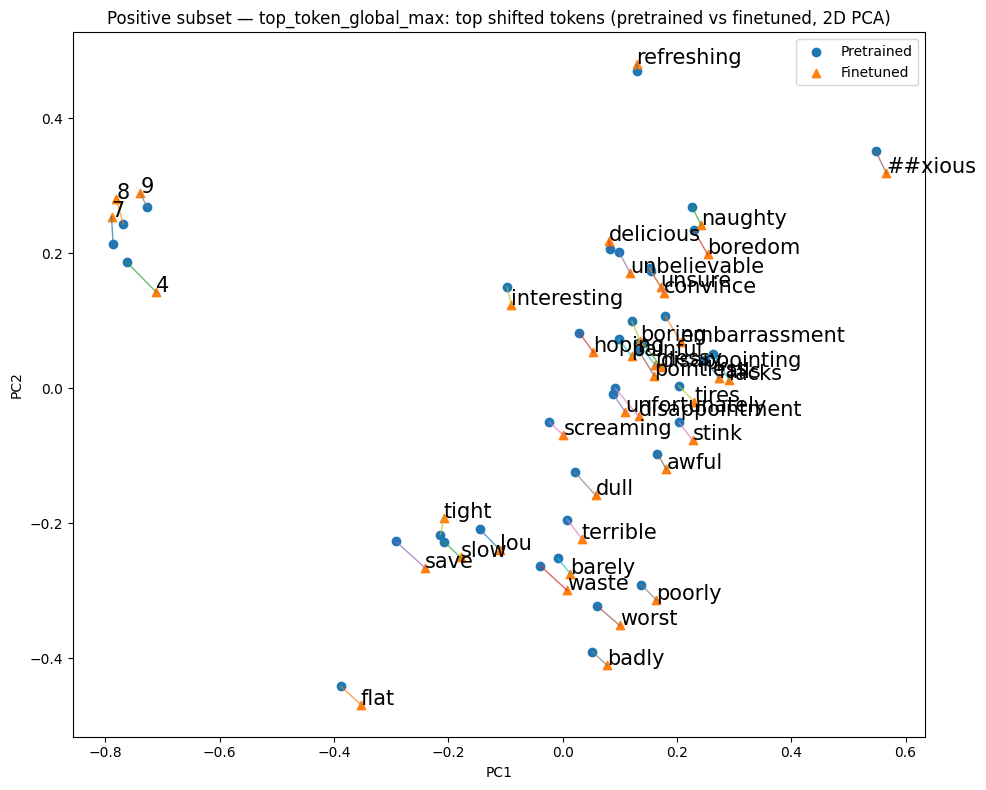

In [26]:
# Extract salient token sets for the positive subset
top_token_cluster_agg_pos = top_tokens_per_cluster_agg(
    R_vocab_pos, cluster_ids_pos, tokenizer, top_n=40
)
top_token_cluster_max_pos = top_tokens_per_cluster_max(
    R_vocab_pos, cluster_ids_pos, tokenizer, top_n=40
)
top_token_global_agg_pos = top_tokens_global_agg(
    R_vocab_pos, tokenizer, top_n=200
)
top_token_global_max_pos = top_tokens_global_max(
    R_vocab_pos, tokenizer, top_n=200
)


# Helper to run the same visual analysis as above
def run_visual_analysis_for_token_set(
    token_set,
    label,
    emb_table_pretrained,
    emb_table_finetuned,
    top_n_metrics=30,
    top_n_pca=40,
):
    token_ids_pretrained, tokens_pretrained, embeddings_pretrained = extract_token_ids_and_tokens(
        token_set, emb_table_pretrained
    )
    token_ids_finetuned, tokens_finetuned, embeddings_finetuned = extract_token_ids_and_tokens(
        token_set, emb_table_finetuned
    )

    E_norm_pretrained = embeddings_pretrained / (
        np.linalg.norm(embeddings_pretrained, axis=1, keepdims=True) + 1e-12
    )
    kmeans_pretrained = KMeans(n_clusters=3, random_state=0, n_init="auto")
    token_clusters_pretrained = kmeans_pretrained.fit_predict(E_norm_pretrained)

    E_norm_finetuned = embeddings_finetuned / (
        np.linalg.norm(embeddings_finetuned, axis=1, keepdims=True) + 1e-12
    )
    kmeans_finetuned = KMeans(n_clusters=3, random_state=0, n_init="auto")
    token_clusters_finetuned = kmeans_finetuned.fit_predict(E_norm_finetuned)

    results = analyze_and_plot_three_metrics(
        token_ids_pretrained=token_ids_pretrained,
        tokens_pretrained=tokens_pretrained,
        embeddings_pretrained=embeddings_pretrained,
        token_ids_finetuned=token_ids_finetuned,
        tokens_finetuned=tokens_finetuned,
        embeddings_finetuned=embeddings_finetuned,
        top_n=top_n_metrics,
    )

    ids, toks, pre_emb, fin_emb = align_by_token_id(
        token_ids_pretrained, tokens_pretrained, embeddings_pretrained,
        token_ids_finetuned, tokens_finetuned, embeddings_finetuned
    )

    plot_token_pairs_pca2(
        tokens=toks,
        pre_emb=pre_emb,
        fin_emb=fin_emb,
        top_n=top_n_pca,
        title=f"{label}: top shifted tokens (pretrained vs finetuned, 2D PCA)",
    )

    return {
        "results": results,
        "token_ids_pretrained": token_ids_pretrained,
        "tokens_pretrained": tokens_pretrained,
        "embeddings_pretrained": embeddings_pretrained,
        "token_ids_finetuned": token_ids_finetuned,
        "tokens_finetuned": tokens_finetuned,
        "embeddings_finetuned": embeddings_finetuned,
        "token_clusters_pretrained": token_clusters_pretrained,
        "token_clusters_finetuned": token_clusters_finetuned,
    }


# Run the four positive-subset visual analyses
positive_cluster_agg_analysis = run_visual_analysis_for_token_set(
    top_token_cluster_agg_pos,
    label="Positive subset — top_token_cluster_agg",
    emb_table_pretrained=emb_table_pretrained,
    emb_table_finetuned=emb_table_finetuned,
)

positive_cluster_max_analysis = run_visual_analysis_for_token_set(
    top_token_cluster_max_pos,
    label="Positive subset — top_token_cluster_max",
    emb_table_pretrained=emb_table_pretrained,
    emb_table_finetuned=emb_table_finetuned,
)

positive_global_agg_analysis = run_visual_analysis_for_token_set(
    top_token_global_agg_pos,
    label="Positive subset — top_token_global_agg",
    emb_table_pretrained=emb_table_pretrained,
    emb_table_finetuned=emb_table_finetuned,
)

positive_global_max_analysis = run_visual_analysis_for_token_set(
    top_token_global_max_pos,
    label="Positive subset — top_token_global_max",
    emb_table_pretrained=emb_table_pretrained,
    emb_table_finetuned=emb_table_finetuned,
)

## Inspecting Token Drift over whole Vocab

In [27]:
def rank_token_embedding_drift(
    tokenizer,
    emb_pretrained,
    emb_finetuned,
    token_ids=None,
    normalize=False,
    eps=1e-12,
):
    """
    Compare pretrained vs finetuned embeddings for the same token ids
    and rank tokens by Euclidean distance (descending).
    Also returns cosine similarity and cosine distance.

    tokenizer: tokenizer object with convert_ids_to_tokens
    emb_pretrained: np.ndarray (vocab_size, dim)
    emb_finetuned:  np.ndarray (vocab_size, dim)
    token_ids: optional iterable of token ids to restrict analysis
    normalize: if True, L2-normalize embeddings before comparison (affects Euclidean; cosine is computed via its own normalization)
    eps: numerical stability constant for cosine normalization

    Returns: pandas.DataFrame sorted by descending Euclidean distance
    """

    emb_pretrained = np.asarray(emb_pretrained, dtype=np.float64)
    emb_finetuned  = np.asarray(emb_finetuned,  dtype=np.float64)

    assert emb_pretrained.shape == emb_finetuned.shape, \
        "Embedding tables must have identical shape."

    if token_ids is None:
        token_ids = np.arange(emb_pretrained.shape[0], dtype=np.int64)
    else:
        token_ids = np.asarray(list(token_ids), dtype=np.int64)

    # Select only the requested rows (tokens)
    E_pre  = emb_pretrained[token_ids]
    E_fine = emb_finetuned[token_ids]

    # Optional global L2 normalization (row-wise) before Euclidean comparison
    if normalize:
        pre_norms  = np.linalg.norm(E_pre,  axis=1, keepdims=True)
        fine_norms = np.linalg.norm(E_fine, axis=1, keepdims=True)
        E_pre  = E_pre  / (pre_norms  + eps)
        E_fine = E_fine / (fine_norms + eps)

    # Euclidean distance per token (row-wise)
    euclidean = np.linalg.norm(E_pre - E_fine, axis=1)

    # Cosine similarity per token (row-wise) with its own normalization
    pre_norm  = np.linalg.norm(E_pre,  axis=1)
    fine_norm = np.linalg.norm(E_fine, axis=1)
    denom = (pre_norm * fine_norm) + eps

    cosine_sim = np.sum(E_pre * E_fine, axis=1) / denom
    cosine_sim = np.clip(cosine_sim, -1.0, 1.0)  # guard against tiny numeric overshoots
    cosine_dist = 1.0 - cosine_sim

    # Build DataFrame
    tokens = tokenizer.convert_ids_to_tokens(token_ids.tolist())

    df = pd.DataFrame({
        "token_id": token_ids,
        "token": tokens,
        "euclidean_distance": euclidean,
        "cosine_distance": cosine_dist,
    })

    df = df.sort_values("euclidean_distance", ascending=False).reset_index(drop=True)
    return df


In [28]:
df_drift = rank_token_embedding_drift(
    tokenizer,
    emb_table_pretrained,
    emb_table_finetuned,
    normalize=False
)

df_drift.sort_values("cosine_distance",ascending=False).head(50)

,token_id,token,euclidean_distance,cosine_distance
0,1021,7,0.217723,0.022723
1,1022,8,0.206475,0.019820
3,1018,4,0.185523,0.017892
7,3105,job,0.165074,0.010912
18,2743,ran,0.158593,0.010808
20,4799,wooden,0.156389,0.010389
39,2145,still,0.146788,0.010377
47,2509,##3,0.143235,0.010161
36,2800,available,0.147568,0.009760
32,2821,oh,0.149979,0.009628


In [29]:
print(df_drift["euclidean_distance"].mean())
print(df_drift["euclidean_distance"].max())
print(df_drift["cosine_distance"].mean())
print(df_drift["cosine_distance"].max())

0.040853205368342714
0.21772298371973983
0.000656699641540776
0.022722960581501805


Clustering over whole vocab

,n,mean_euc,mean_cos,mean_centroid_dist
cluster,,,,
3,297,0.107034,0.003402,0.370243
4,211,0.109429,0.003711,0.373865
1,186,0.106752,0.002497,0.347263
0,161,0.110176,0.005195,0.477535
2,145,0.106317,0.003123,0.375872



=== Cluster 0 (n=161) ===


,token_id,token,euclidean_distance,cosine_distance,centroid_dist
0,1021,7,0.217723,0.022723,0.657727
1,1022,8,0.206475,0.019820,0.655279
3,1018,4,0.185523,0.017892,0.695492
7,3105,job,0.165074,0.010912,0.441632
12,3828,save,0.163465,0.008900,0.568973
18,2743,ran,0.158593,0.010808,0.466627
19,3902,bus,0.158513,0.009496,0.437593
31,5796,ms,0.150240,0.006997,0.400362
32,2821,oh,0.149979,0.009628,0.472152
36,2800,available,0.147568,0.009760,0.479924



=== Cluster 1 (n=186) ===


,token_id,token,euclidean_distance,cosine_distance,centroid_dist
5,21564,##eem,0.181871,0.005507,0.325227
8,10830,##awa,0.164981,0.004971,0.314537
16,5149,##dy,0.159374,0.006207,0.371183
24,8785,math,0.152907,0.006737,0.427003
29,18447,##int,0.151206,0.004150,0.384070
35,19960,med,0.147629,0.005829,0.409814
44,10695,##nn,0.144886,0.004231,0.282019
56,15937,##ech,0.140093,0.003285,0.262946
63,16748,##cre,0.136755,0.003026,0.360862
67,10223,lou,0.135222,0.004561,0.376712



=== Cluster 2 (n=145) ===


,token_id,token,euclidean_distance,cosine_distance,centroid_dist
2,27430,##titles,0.195347,0.007069,0.390809
11,12887,##birds,0.163704,0.005982,0.311632
37,27984,blah,0.146854,0.004353,0.358486
38,17550,vhs,0.146822,0.005082,0.353386
41,15803,bourne,0.145553,0.005783,0.438636
42,3085,##able,0.145524,0.006390,0.457705
55,13226,vanessa,0.140637,0.006375,0.333803
64,15164,##avia,0.135862,0.003357,0.365195
71,7101,drummer,0.133852,0.006086,0.390347
76,8074,expecting,0.132893,0.005149,0.399672



=== Cluster 3 (n=297) ===


,token_id,token,euclidean_distance,cosine_distance,centroid_dist
4,13904,chamberlain,0.184918,0.009601,0.323934
9,12578,marty,0.164736,0.007611,0.345289
14,17489,natal,0.161122,0.005518,0.358201
23,6634,panic,0.153443,0.008276,0.446780
27,13711,complement,0.151968,0.005989,0.346433
33,27503,flawless,0.149198,0.005474,0.360314
34,16075,mccoy,0.148667,0.005770,0.301999
40,14433,kitty,0.146569,0.005615,0.403388
48,6530,dirty,0.143224,0.006748,0.518494
58,11804,hyde,0.139160,0.004856,0.366475



=== Cluster 4 (n=211) ===


,token_id,token,euclidean_distance,cosine_distance,centroid_dist
6,8797,boom,0.175841,0.008831,0.481082
10,5949,waste,0.163729,0.007696,0.463607
13,12382,generous,0.161518,0.007841,0.329706
15,5409,worst,0.159913,0.007534,0.441801
17,10520,disappointment,0.159043,0.008925,0.367066
20,4799,wooden,0.156389,0.010389,0.450219
21,24591,believer,0.155333,0.005051,0.313999
22,6752,mess,0.154432,0.006442,0.446163
25,10970,baldwin,0.152403,0.006928,0.322471
26,6701,mason,0.152312,0.008937,0.482217


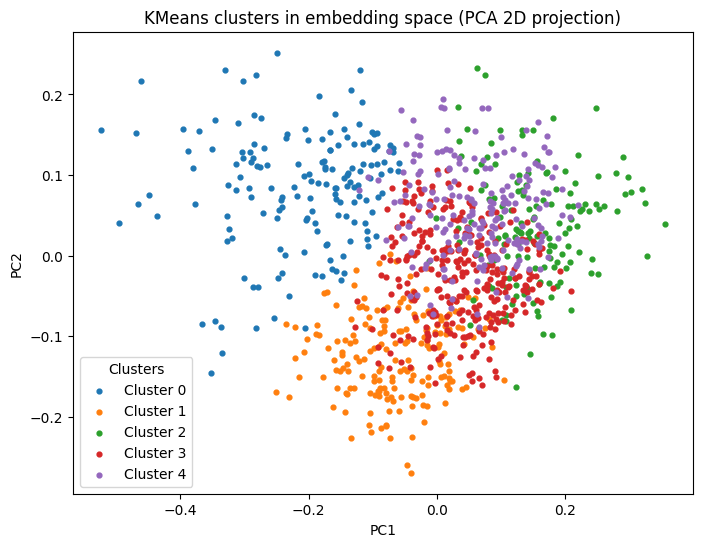

In [30]:
def cluster_top_tokens_in_embedding_space(
    df_drift,
    emb_pretrained,
    emb_finetuned,
    space="finetuned", #  or "pretrained"
    top_n=1000,
    k=10,
    l2_normalize=True,
    pca_dim=50,# set None to skip PCA
    random_state=0,
):
    top = df_drift.head(top_n).copy()
    ids = top["token_id"].to_numpy(dtype=np.int64)

    emb_pre = np.asarray(emb_pretrained, dtype=np.float64)
    emb_fin = np.asarray(emb_finetuned,  dtype=np.float64)

    if emb_pre.shape != emb_fin.shape:
        raise ValueError(f"Embedding tables mismatch: pre={emb_pre.shape}, fin={emb_fin.shape}")
    if ids.max(initial=0) >= emb_pre.shape[0]:
        raise ValueError("Some token_id exceed vocab size of embedding tables.")

    # Choose which embedding space to cluster in
    if space == "finetuned":
        E = emb_fin[ids]   # (top_n, d)
    elif space == "pretrained":
        E = emb_pre[ids]
    else:
        raise ValueError("space must be 'finetuned' or 'pretrained'")

    # Optional L2-normalization (often desirable for embeddings)
    if l2_normalize:
        norms = np.linalg.norm(E, axis=1, keepdims=True)
        E = E / (norms + 1e-12)

    # Optional PCA before KMeans (helps in very high-d spaces)
    X = E
    if pca_dim is not None:
        p = PCA(n_components=min(pca_dim, X.shape[1]), random_state=random_state)
        X = p.fit_transform(X)

    # KMeans clustering
    km = KMeans(n_clusters=k, random_state=random_state, n_init="auto")
    labels = km.fit_predict(X)
    top["cluster"] = labels

    # Representative tokens: closest to cluster centroid
    centroids = km.cluster_centers_
    top["centroid_dist"] = np.linalg.norm(X - centroids[labels], axis=1)

    # Cluster summary
    cluster_stats = (top.groupby("cluster")
                       .agg(n=("token_id","size"),
                            mean_euc=("euclidean_distance","mean"),
                            mean_cos=("cosine_distance","mean"),
                            mean_centroid_dist=("centroid_dist","mean"))
                       .sort_values("n", ascending=False))

    return top, cluster_stats, X, labels

# --- run ---
top_clustered, cluster_stats, X_used, labels = cluster_top_tokens_in_embedding_space(
    df_drift=df_drift,
    emb_pretrained=emb_table_pretrained,
    emb_finetuned=emb_table_finetuned,
    space="finetuned",   # or "pretrained"
    top_n=1000,
    k=5,
    l2_normalize=True,
    pca_dim=50,
)

display(cluster_stats)

# Inspect representative tokens per cluster (most "typical" first)
for c in sorted(top_clustered["cluster"].unique()):
    print(f"\n=== Cluster {c} (n={int((top_clustered['cluster'] == c).sum())}) ===")
    display(
        top_clustered[top_clustered["cluster"] == c]
        .sort_values( "euclidean_distance", ascending=False)
        .head(20)[["token_id", "token", "euclidean_distance", "cosine_distance", "centroid_dist"]]
    )

# 2D visualization for inspection (PCA projection)
p2 = PCA(n_components=2, random_state=0)
XY = p2.fit_transform(X_used)

plt.figure(figsize=(8, 6))

for c in sorted(np.unique(labels)):
    mask = labels == c
    plt.scatter(
        XY[mask, 0],
        XY[mask, 1],
        s=12,
        label=f"Cluster {c}"
    )

plt.title("KMeans clusters in embedding space (PCA 2D projection)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Clusters")
plt.show()


In [31]:
top_clustered[top_clustered["token"].isin([str(i)for i in range(0,11)])]

,token_id,token,euclidean_distance,cosine_distance,cluster,centroid_dist
0,1021,7,0.217723,0.022723,0,0.657727
1,1022,8,0.206475,0.019820,0,0.655279
3,1018,4,0.185523,0.017892,0,0.695492
152,1017,3,0.121803,0.007729,0,0.708589
295,1023,9,0.111613,0.005771,0,0.643573
448,1015,1,0.104944,0.005646,0,0.646736
600,1016,2,0.099804,0.004959,0,0.702881


---

Observation: Similar Results for Positive Subset

---

## Analyste Tokens in context with corresponding Clusters
Clustering is based on S1 Saliency Vocab

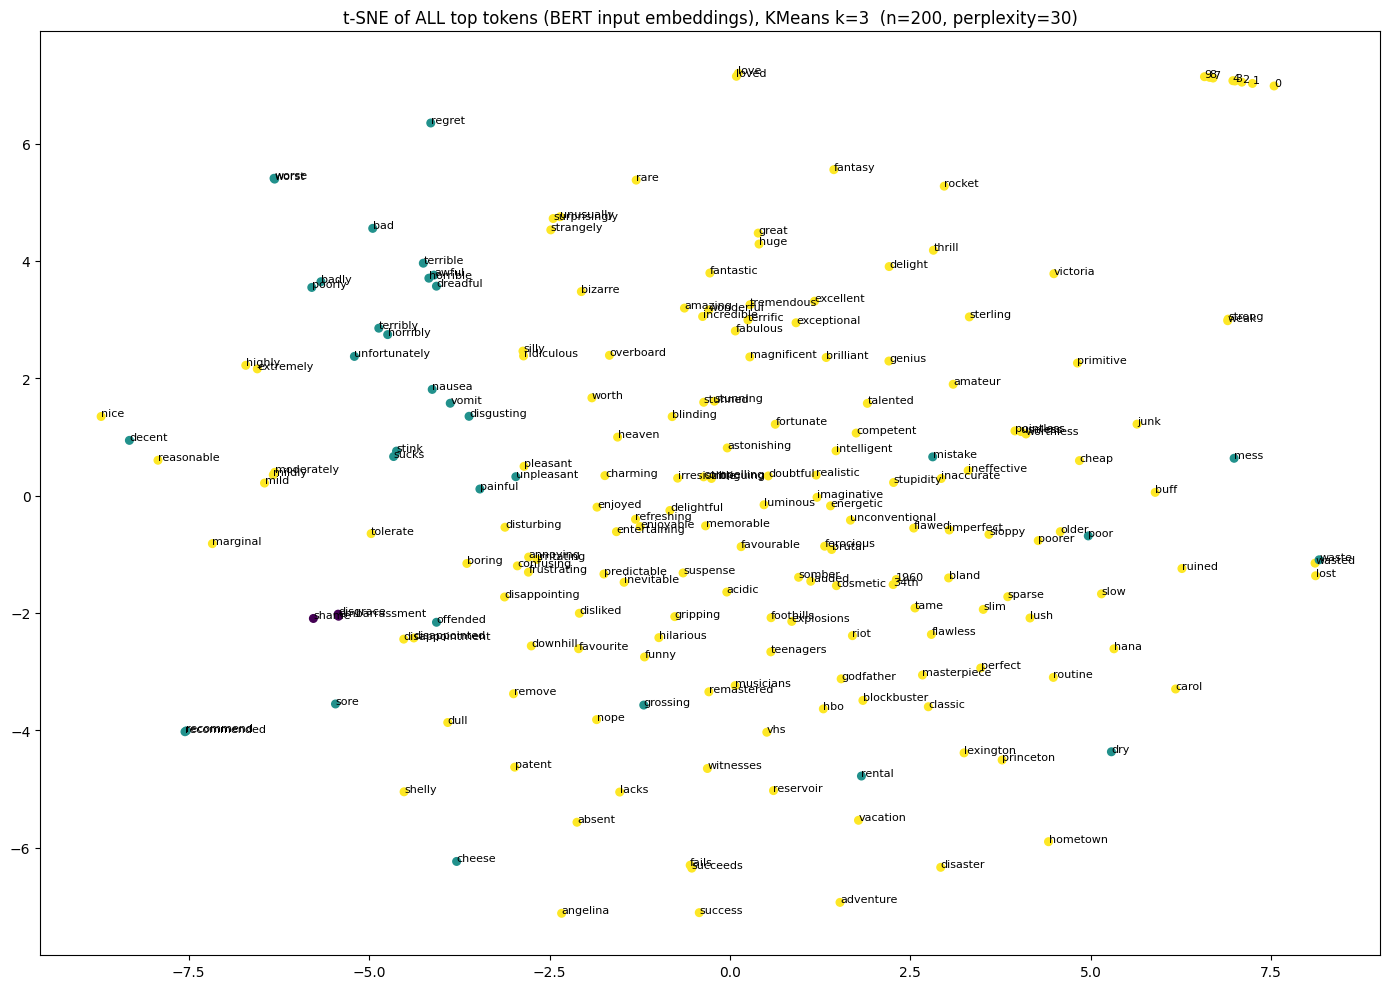

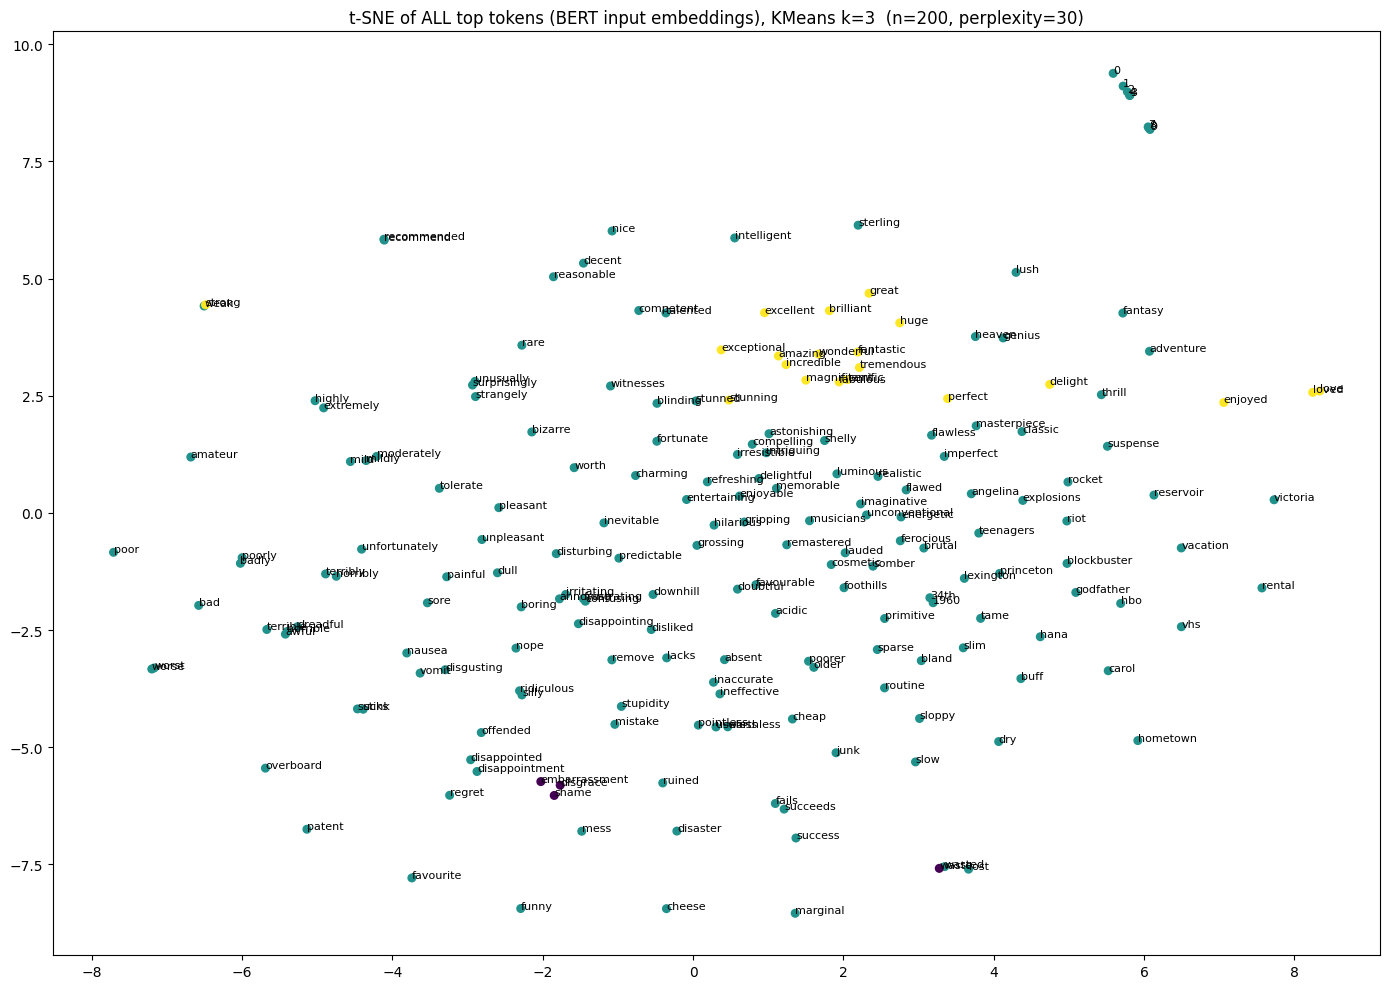

In [32]:
def tsne_plot_tokens_colored(tokens, E, labels, title="t-SNE token embeddings (colored by KMeans)",
                             label_top_n=None, figsize=(14,10), random_state=0):
    n = E.shape[0]
    if n < 3:
        return

    # perplexity must be < n; good heuristic for 50–500 points
    perplexity = min(30, max(5, (n - 1) // 3))

    X2 = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=random_state,
        init="pca",
        learning_rate="auto"
    ).fit_transform(E)

    plt.figure(figsize=figsize)
    sc = plt.scatter(X2[:, 0], X2[:, 1], c=labels, s=30)

    # optional labeling: label a subset of tokens
    if label_top_n is not None and label_top_n > 0:
        # label a spread of points: take first label_top_n by distance from global mean (more informative than random)
        mu = X2.mean(axis=0, keepdims=True)
        d = np.linalg.norm(X2 - mu, axis=1)
        idx = np.argsort(-d)[:min(label_top_n, n)]
        for i in idx:
            plt.text(X2[i, 0], X2[i, 1], tokens[i], fontsize=8)

    plt.title(f"{title}  (n={n}, perplexity={perplexity})")
    plt.tight_layout()
    plt.show()

tsne_plot_tokens_colored(tokens_pretrained, E_norm_pretrained, token_clusters_pretrained,
                         title=f"t-SNE of ALL top tokens (BERT input embeddings), KMeans k={k}",
                         label_top_n=200)

tsne_plot_tokens_colored(tokens_finetuned, E_norm_finetuned, token_clusters_finetuned,
                         title=f"t-SNE of ALL top tokens (BERT input embeddings), KMeans k={k}",
                         label_top_n=200)


---
## Further Experiments on Clusters based on S1 Saliency

Introducing Pre-Trained Cluster Distance (PCD) and Finetuned Cluster Distance (FCD)


1. Calculating PCD: Pre Trained Cluster Distance: 
2. Calculating FCD: Finetuned Cluster Distance

Low PCD: Pretrained and Fine Tuned Model somewhat agree on proximity towards clauster
High PCD: Pretrained Models internal representation points towards a strong shift in relative meaning of a token (wrt. to the cluster)

In [33]:
def salient_tokens_to_df(token_groups):
    """
    Convert either:
      1) cluster dict: {cluster_id: [(token_id, token, saliency), ...], ...}
      2) global list:  [(token_id, token, saliency), ...]
    into a single DataFrame.
    """
    rows = []

    # case 1: cluster-wise dict
    if isinstance(token_groups, dict):
        for cluster_id, items in token_groups.items():
            for token_id, token_str, saliency in items:
                rows.append({
                    "cluster_id": int(cluster_id),
                    "token_id": int(token_id),
                    "token": str(token_str),
                    "saliency": float(saliency),
                })

    # case 2: global list
    else:
        for token_id, token_str, saliency in token_groups:
            rows.append({
                "cluster_id": 0,  # pseudo-cluster for global token lists
                "token_id": int(token_id),
                "token": str(token_str),
                "saliency": float(saliency),
            })

    return pd.DataFrame(rows)


def run_token_pca_pipeline(
    token_groups,
    emb_table_pretrained,
    emb_table_finetuned,
    tokenizer,
    highlight_tokens=None,
    title_prefix="",
    figsize=(20, 9),
):
    """
    Build saliency df, project selected tokens into embedding space,
    run PCA, and plot 3D + 2D finetuned embeddings.

    Returns:
        saliency_df, fig, (ax1_3d, ax2_2d)
    """
    if highlight_tokens is None:
        highlight_tokens = ["1", "2", "3", "4", "5", "6", "7", "8", "9", "0", "/"]

    # convert token groups -> dataframe
    saliency_df = salient_tokens_to_df(token_groups).copy()

    if saliency_df.empty:
        raise ValueError("token_groups produced an empty DataFrame.")

    token_ids = saliency_df["token_id"].to_numpy()

    # support torch tensors or numpy arrays
    if hasattr(emb_table_finetuned, "detach"):
        emb_fine = emb_table_finetuned[token_ids].detach().cpu().numpy()
    else:
        emb_fine = np.asarray(emb_table_finetuned[token_ids])

    if hasattr(emb_table_pretrained, "detach"):
        emb_pre = emb_table_pretrained[token_ids].detach().cpu().numpy()
    else:
        emb_pre = np.asarray(emb_table_pretrained[token_ids])

    # PCA separately for finetuned / pretrained, matching your current code
    pca_fine = PCA(n_components=3, random_state=0)
    pca_pre = PCA(n_components=3, random_state=0)

    pcs_fine = pca_fine.fit_transform(emb_fine)
    pcs_pre = pca_pre.fit_transform(emb_pre)

    # add PCA columns
    saliency_df[["pc1_finetuned", "pc2_finetuned", "pc3_finetuned"]] = pcs_fine
    saliency_df[["pc1_2d", "pc2_2d"]] = pcs_fine[:, :2]
    saliency_df[["pc1_pretrained", "pc2_pretrained", "pc3_pretrained"]] = pcs_pre

    # optional: highlight token ids too, in case you want to inspect
    highlight_ids = tokenizer.convert_tokens_to_ids(highlight_tokens)
    saliency_df["is_highlight"] = saliency_df["token"].isin(highlight_tokens)
    saliency_df["is_highlight_id"] = saliency_df["token_id"].isin(highlight_ids)

    # plot
    fig = plt.figure(figsize=figsize)
    ax1 = fig.add_subplot(121, projection="3d")
    ax2d = fig.add_subplot(122)

    for cluster_id, g in saliency_df.groupby("cluster_id"):
        ax2d.scatter(
            g["pc1_2d"], g["pc2_2d"],
            s=40, alpha=0.8, label=f"cluster {cluster_id}"
        )

    for cluster_id, g in saliency_df.groupby("cluster_id"):
        ax1.scatter(
            g["pc1_finetuned"], g["pc2_finetuned"], g["pc3_finetuned"],
            s=40, label=f"cluster {cluster_id}", depthshade=False
        )

    # highlight selected tokens
    g_hi = saliency_df[saliency_df["is_highlight"]]

    for _, r in g_hi.iterrows():
        ax1.text(
            r["pc1_finetuned"], r["pc2_finetuned"], r["pc3_finetuned"],
            str(r["token"]), fontsize=9
        )

    for _, r in g_hi.iterrows():
        ax2d.text(
            r["pc1_2d"], r["pc2_2d"],
            str(r["token"]), fontsize=9
        )

    ax2d.set_title(f"{title_prefix} 2D PCA (finetuned)".strip())
    ax2d.set_xlabel("PC1")
    ax2d.set_ylabel("PC2")
    ax2d.legend(loc="best", fontsize=8)

    ax1.set_title(f"{title_prefix} 3D PCA (finetuned)".strip())
    ax1.set_xlabel("PC1")
    ax1.set_ylabel("PC2")
    ax1.set_zlabel("PC3")
    ax1.legend(loc="best", fontsize=8)

    plt.tight_layout()
    plt.show()

    return saliency_df, fig, (ax1, ax2d)


def run_token_pca_pipeline_for_many(
    token_group_dict,
    emb_table_pretrained,
    emb_table_finetuned,
    tokenizer,
    highlight_tokens=None,
):
    """
    Run the PCA pipeline for multiple token groups.

    token_group_dict example:
    {
        "cluster_agg": top_token_cluster_agg_top_5,
        "cluster_max": top_tokens_per_cluster_max_top_5,
        "global_agg": top_token_global_agg_top_5,
        "global_max": top_token_global_max_top_5,
    }

    Returns:
        results[name] = {
            "df": saliency_df,
            "fig": fig,
            "axes": (ax1, ax2d),
        }
    """
    results = {}

    for name, token_groups in token_group_dict.items():
        df, fig, axes = run_token_pca_pipeline(
            token_groups=token_groups,
            emb_table_pretrained=emb_table_pretrained,
            emb_table_finetuned=emb_table_finetuned,
            tokenizer=tokenizer,
            highlight_tokens=highlight_tokens,
            title_prefix=name,
        )
        results[name] = {
            "df": df,
            "fig": fig,
            "axes": axes,
        }

    return results

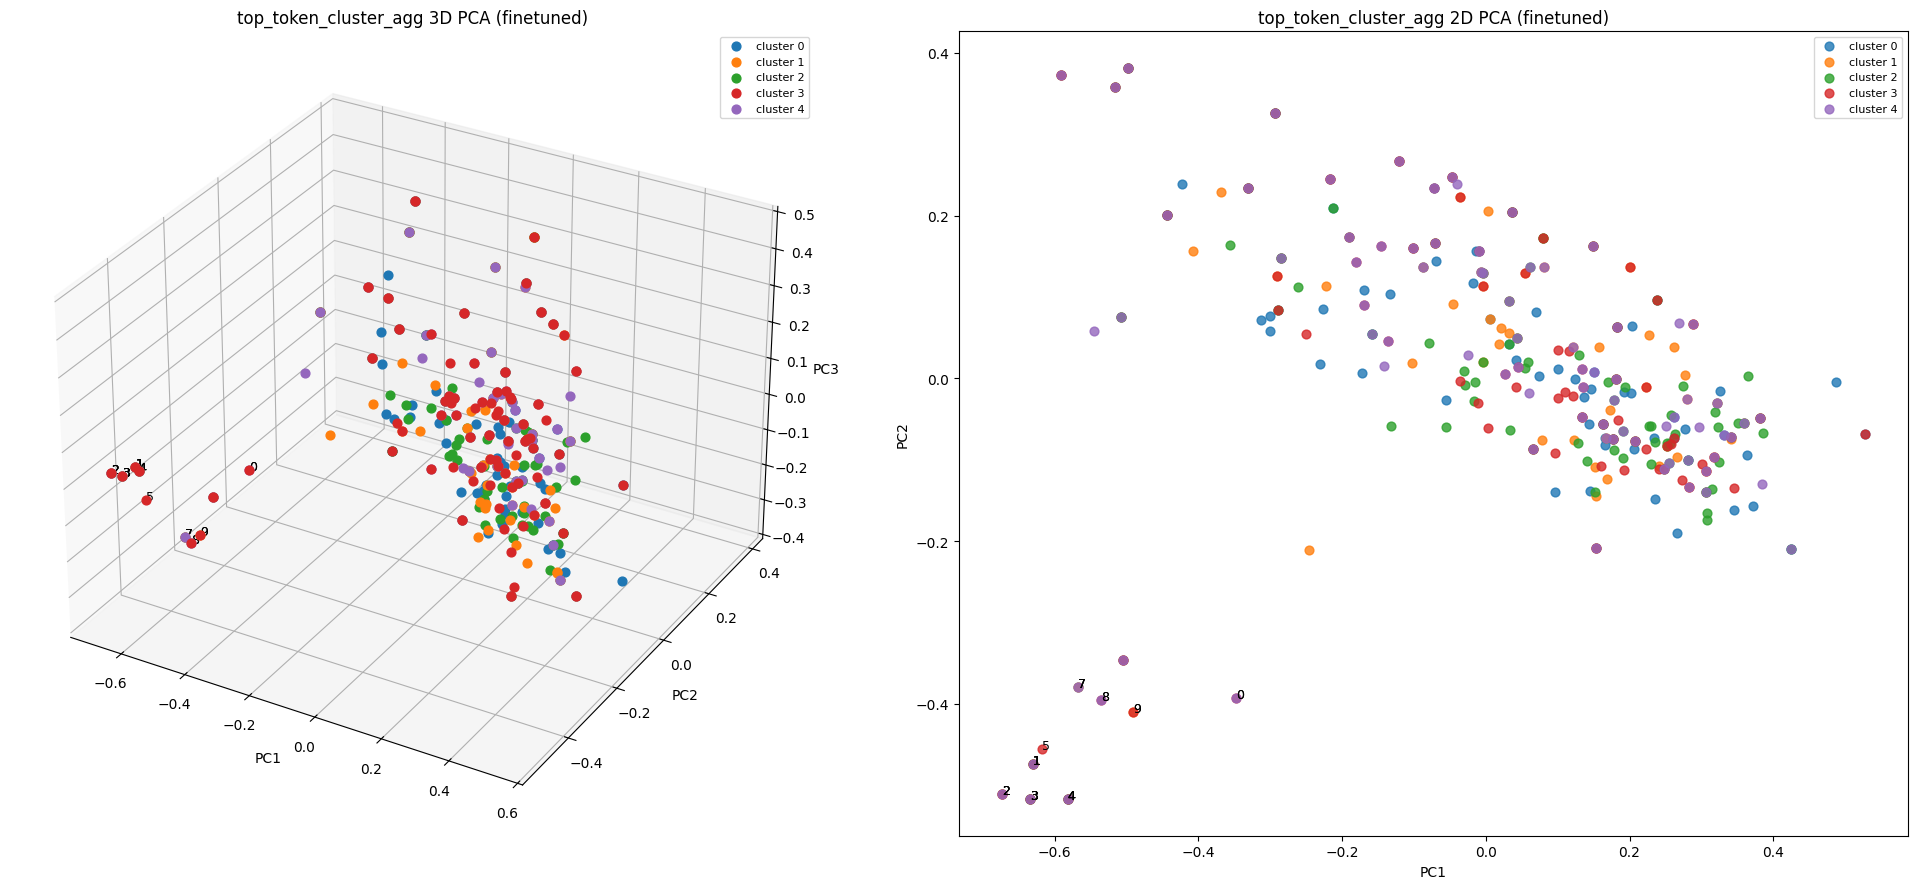

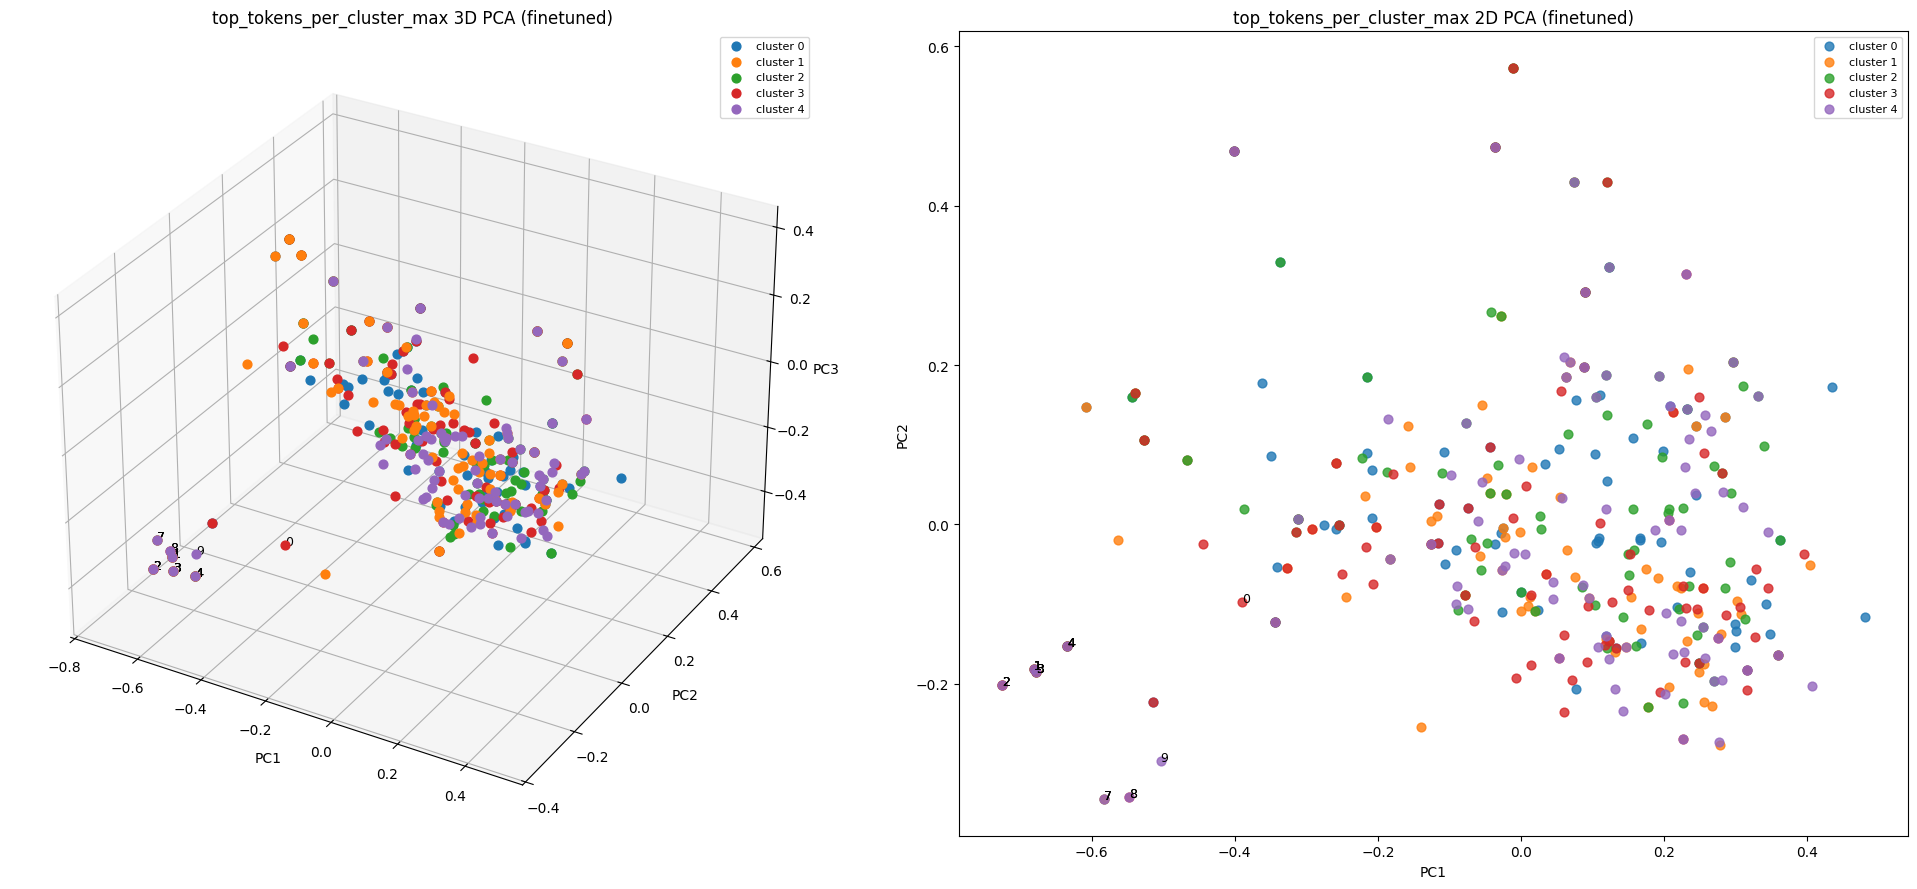

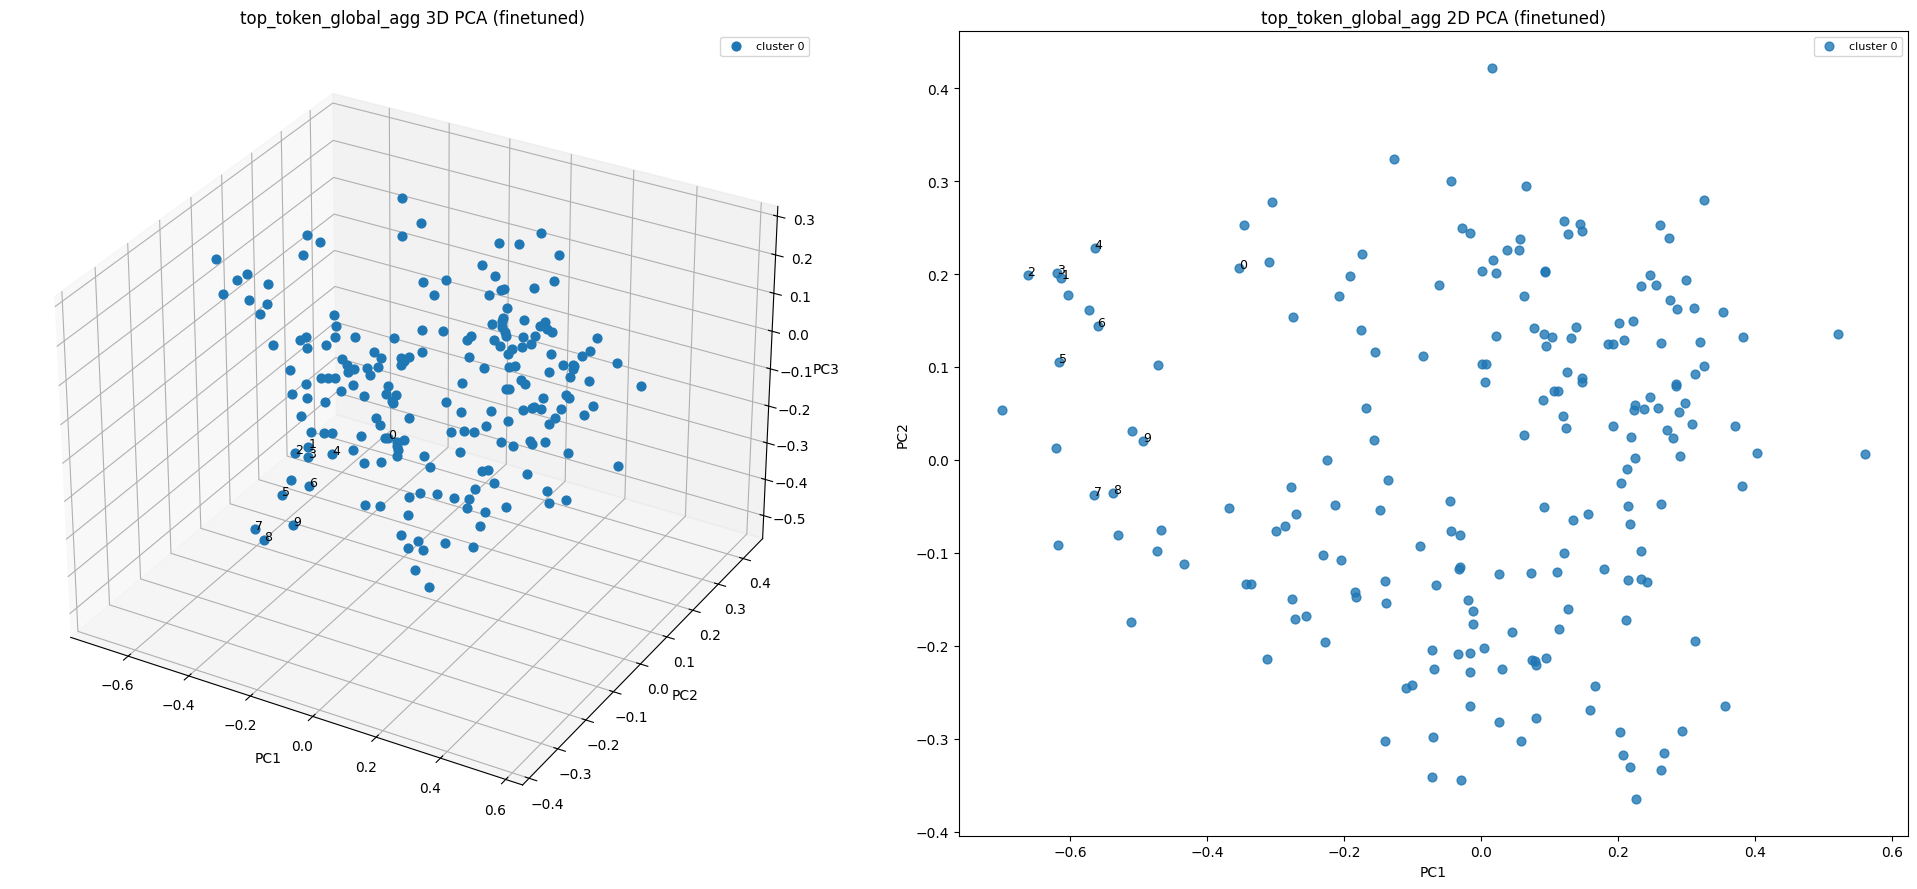

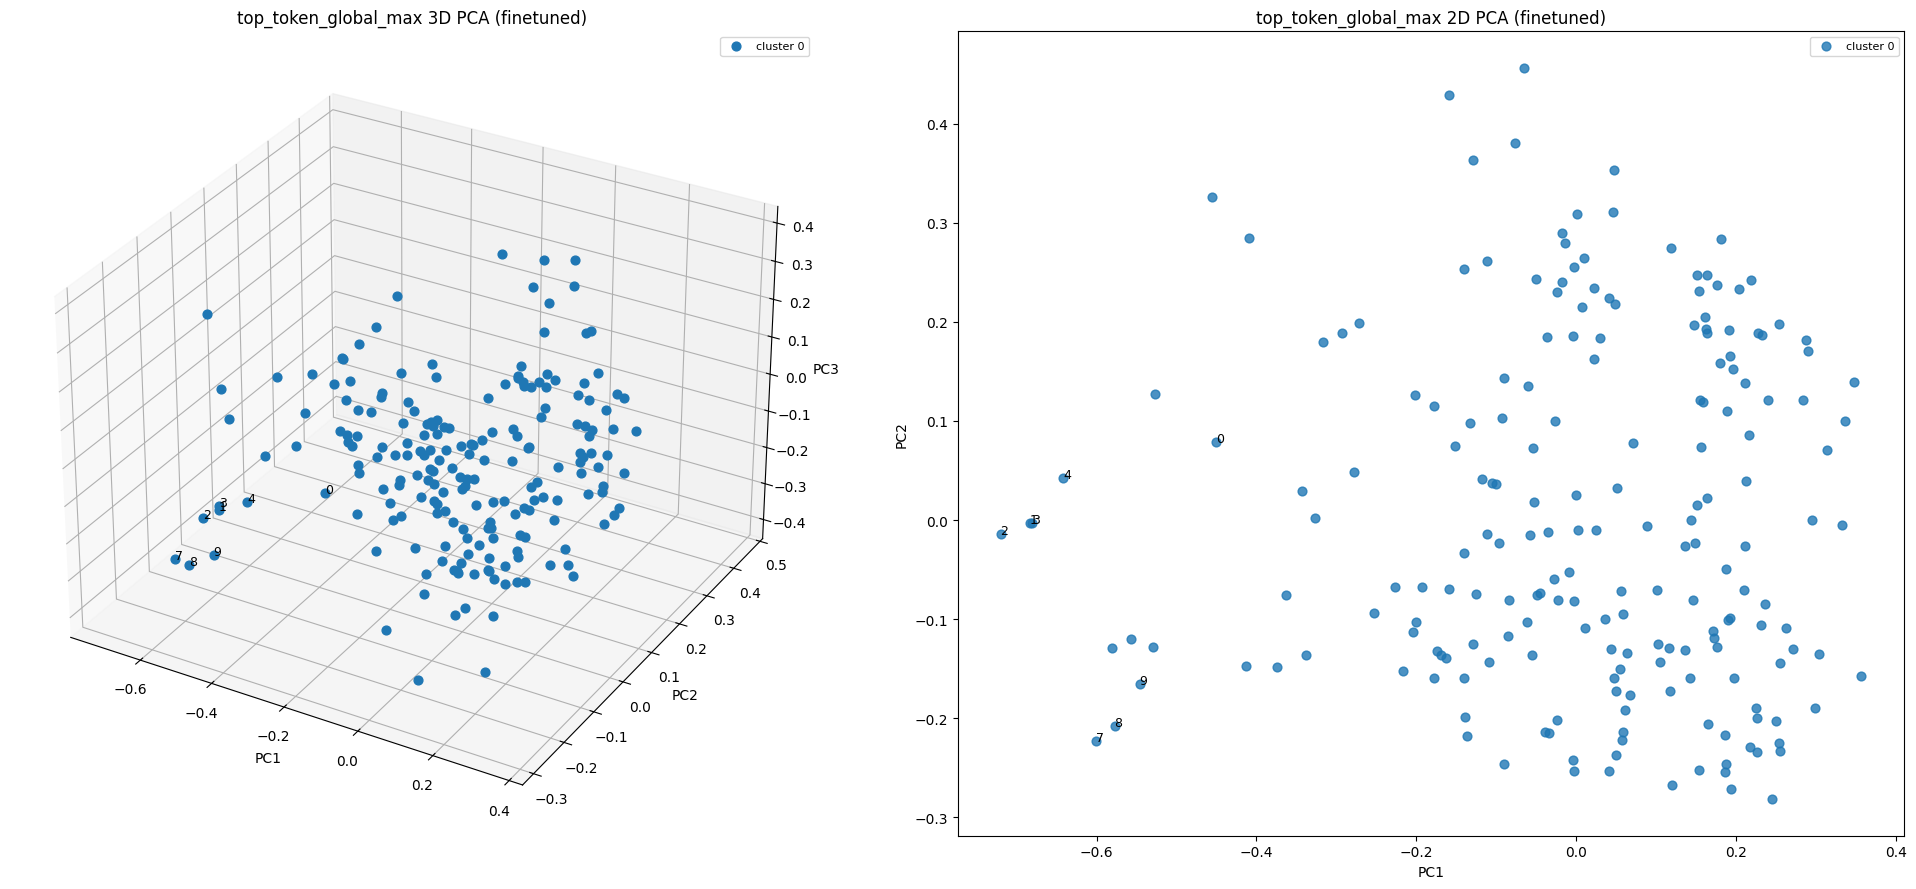

In [34]:
# groups
top_token_cluster_agg_top_5 = top_tokens_per_cluster_agg(R_vocab, cluster_ids, tokenizer, top_n=80)
top_tokens_per_cluster_max_top_5 = top_tokens_per_cluster_max(R_vocab, cluster_ids, tokenizer, top_n=80)
top_token_global_agg_top_5 = top_tokens_global_agg(R_vocab, tokenizer, top_n=200)
top_token_global_max_top_5 = top_tokens_global_max(R_vocab, tokenizer, top_n=200)

# highlight tokens
highlight_tokens = ["1", "2", "3", "4", "5", "6", "7", "8", "9", "0", "/"]

token_groups_all = {
    "top_token_cluster_agg": top_token_cluster_agg_top_5,
    "top_tokens_per_cluster_max": top_tokens_per_cluster_max_top_5,
    "top_token_global_agg": top_token_global_agg_top_5,
    "top_token_global_max": top_token_global_max_top_5,
}

results = run_token_pca_pipeline_for_many(
    token_group_dict=token_groups_all,
    emb_table_pretrained=emb_table_pretrained,
    emb_table_finetuned=emb_table_finetuned,
    tokenizer=tokenizer,
    highlight_tokens=highlight_tokens,
)

Pairwise distance matrix example for sanity check

Embedding_pre =
[
  e₀,
  e₁,
  e₂ 
]

Distance_pre =
[
  [d(e₀,e₀), d(e₀,e₁), d(e₀,e₂)],
  [d(e₁,e₀), d(e₁,e₁), d(e₁,e₂)],
  [d(e₂,e₀), d(e₂,e₁), d(e₂,e₂)]
]

In [35]:
def token_cluster_distances(
    clusters: dict,
    embeddings_pretrained,
    embeddings_finetuned,
    distance = "cosine"
):
    """
    Computes PCD(w_l) and FCD(w_l) using sklearn distance functions.
    """
    
    # Tensor -> numpy array. SKLearn expects np arrays
    if not isinstance(embeddings_pretrained, np.ndarray):
        embeddings_pretrained = embeddings_pretrained.detach().cpu().numpy()
    if not isinstance(embeddings_finetuned, np.ndarray):
        embeddings_finetuned = embeddings_finetuned.detach().cpu().numpy()

    if distance == "cosine":
        distance_metric = cosine_distances
    elif distance == "euclidean":
        distance_metric = euclidean_distances
    else:
        raise ValueError("distance must be 'cosine' or 'euclidean'")

    results = {}

    rows = []

    # iterate over clusters
    for cluster_id, token_list in clusters.items():
        #extract token ids
        token_ids = [t[0] for t in token_list]
        N = len(token_ids)

        # convert tokens to embeddings
        Embedding_pre = embeddings_pretrained[token_ids] # (30522, 768) ->  (N, 768) (One row per token)
        Embedding_fine = embeddings_finetuned[token_ids] # (30522, 768) ->  (N, 768)

        # Compute distance betweene very pair of rows in embedding_pre (diagonal = 0)
        Distance_pre = distance_metric(Embedding_pre) # (N,N)
        Distance_fine = distance_metric(Embedding_fine) # (N,N)

        # cluster_dict
        cluster_results = {}

        # iterate over token_list [(token_id, token, salience)...]
        for i, (token_id, token_str, salience) in enumerate(token_list):
            # sum all distances (per row) and divice by n-1 for average (excluding entries matrix[i,i])
            pcd = (Distance_pre[i].sum() - Distance_pre[i, i]) / (N - 1) # second term removes distance to itself
            fcd = (Distance_fine[i].sum() - Distance_fine[i, i]) / (N - 1)
            delta = fcd-pcd

            cluster_results[token_id] = {
                "token": token_str,
                "PCD": float(pcd),
                "FCD": float(fcd),
                "Delta": float(delta),
            }

            rows.append({
                "cluster_id": cluster_id,
                "token_id": token_id,
                "token": token_str,
                "salience": float(salience),
                "PCD": float(pcd),
                "FCD": float(fcd),
                "Delta": float(delta),
            })

        results[cluster_id] = cluster_results

    df_tokens = pd.DataFrame(rows)
    df_tokens["abs_Delta"] = df_tokens["Delta"].abs()


    # Summary
    df_clusters = (
        df_tokens
        .groupby("cluster_id")
        .agg(
            N_tokens=("token_id", "count"),
            PCD_mean=("PCD", "mean"),
            FCD_mean=("FCD", "mean"),
            Delta_mean=("Delta", "mean"),
            Delta_abs_mean=("abs_Delta", "mean"),
            
        )
        .reset_index()
    )


    return results, df_tokens, df_clusters, Distance_pre, Distance_fine


In [36]:
clusters = {
    0: [
        (0, "A", 1.0),
        (1, "B", 1.0),
        (2, "C", 1.0),
    ]
}

embeddings_pretrained = np.array([
    [0, 0],  # A
    [1, 0],  # B
    [0, 1],  # C
])

embeddings_finetuned = np.array([
    [0, 0],  # A
    [1, 1],  # B
    [1, 0],  # C
])

results_test, df_tokens_test,df_clusters_test, dist_pre, dist_fine = token_cluster_distances(clusters,embeddings_pretrained,embeddings_finetuned, "euclidean")
dist_pre, dist_fine 


(array([[0.        , 1.        , 1.        ],
        [1.        , 0.        , 1.41421356],
        [1.        , 1.41421356, 0.        ]]),
 array([[0.        , 1.41421356, 1.        ],
        [1.41421356, 0.        , 1.        ],
        [1.        , 1.        , 0.        ]]))

In [37]:
top_token_cluster_agg_top_5 = top_tokens_per_cluster_agg(R_vocab, cluster_ids, tokenizer, top_n=50)
results, df_tokens,df_clusters, _, _ = token_cluster_distances(top_token_cluster_agg_top_5,emb_table_pretrained,emb_table_finetuned, "cosine")

df_tokens.sort_values(["salience"],ascending = False).head(30)

,cluster_id,token_id,token,salience,PCD,FCD,Delta,abs_Delta
50,1,5409,worst,121.088768,0.644135,0.634332,-0.009803,0.009803
200,4,2919,bad,117.283607,0.683756,0.673753,-0.010003,0.010003
150,3,9643,awful,103.077217,0.577520,0.570129,-0.007391,0.007391
201,4,2307,great,73.094231,0.719045,0.721023,0.001978,0.001978
202,4,6659,terrible,63.313126,0.569876,0.560596,-0.009281,0.009281
203,4,1018,4,60.540611,0.672734,0.661030,-0.011704,0.011704
204,4,5949,waste,50.591801,0.686929,0.671745,-0.015184,0.015184
205,4,11771,boring,47.265541,0.614501,0.606699,-0.007802,0.007802
206,4,9202,horrible,43.787544,0.551862,0.545794,-0.006068,0.006068
207,4,10634,dull,41.394451,0.613746,0.600979,-0.012767,0.012767


In [38]:
Epre  = emb_table_pretrained.detach().cpu().numpy()
Efine = emb_table_finetuned.detach().cpu().numpy()

print("allclose:", np.allclose(Epre, Efine, atol=1e-8))
print("max abs diff:", np.max(np.abs(Efine - Epre)))
print("mean abs diff:", np.mean(np.abs(Efine - Epre)))

allclose: False
max abs diff: 0.016954727
mean abs diff: 0.001231718


In [39]:
diff = Efine - Epre
l2_drift = np.linalg.norm(diff, axis=1)

pre_norm = np.linalg.norm(Epre, axis=1) + 1e-12
rel_l2_drift = l2_drift / pre_norm

cos_sim = np.sum(Epre * Efine, axis=1) / ((np.linalg.norm(Epre, axis=1)+1e-12) * (np.linalg.norm(Efine, axis=1)+1e-12))
cos_drift = 1 - cos_sim

print("L2 drift mean/max:", l2_drift.mean(), l2_drift.max())
print("Relative L2 drift mean/max:", rel_l2_drift.mean(), rel_l2_drift.max())
print("Cos drift mean/max:", cos_drift.mean(), cos_drift.max())


L2 drift mean/max: 0.040853206 0.21772298
Relative L2 drift mean/max: 0.030057631 0.21538933
Cos drift mean/max: 0.0006566976 0.02272296


In [40]:
df_tokens

,cluster_id,token_id,token,salience,PCD,FCD,Delta,abs_Delta
0,0,9364,disappointed,33.721275,0.601296,0.596887,-0.004409,0.004409
1,0,15640,disappointing,3.499961,0.542723,0.538773,-0.003949,0.003949
2,0,2307,great,2.394359,0.720474,0.719630,-0.000844,0.000844
3,0,2919,bad,2.316138,0.703742,0.697205,-0.006537,0.006537
4,0,6659,terrible,2.098763,0.592043,0.587385,-0.004657,0.004657
...,...,...,...,...,...,...,...,...
245,4,13842,wasted,13.241750,0.596171,0.587648,-0.008523,0.008523
246,4,5410,weak,12.400403,0.653879,0.643918,-0.009962,0.009962
247,4,11519,decent,12.368776,0.603500,0.602626,-0.000874,0.000874
248,4,10889,surprisingly,12.211670,0.594668,0.594060,-0.000608,0.000608


In [41]:
df_tokens[df_tokens["token"].isin([str(i) for i in range(0,11)])]

,cluster_id,token_id,token,salience,PCD,FCD,Delta,abs_Delta
14,0,1021,7,1.183456,0.687493,0.687699,0.000206,0.000206
23,0,1017,3,0.906428,0.725101,0.723067,-0.002034,0.002034
27,0,1016,2,0.837220,0.741984,0.740661,-0.001323,0.001323
55,1,1016,2,7.629426,0.722433,0.720841,-0.001592,0.001592
56,1,1015,1,7.492280,0.727310,0.722965,-0.004345,0.004345
57,1,1018,4,6.343622,0.694372,0.685171,-0.009201,0.009201
59,1,1017,3,6.202840,0.707080,0.704600,-0.002480,0.002480
78,1,2184,10,2.069337,0.664508,0.668233,0.003724,0.003724
103,2,1015,1,2.130600,0.729522,0.723684,-0.005837,0.005837
111,2,1017,3,1.052731,0.707972,0.703620,-0.004352,0.004352


In [42]:
df_clusters

,cluster_id,N_tokens,PCD_mean,FCD_mean,Delta_mean,Delta_abs_mean
0,0,50,0.646526,0.644329,-0.002198,0.002796
1,1,50,0.637005,0.634157,-0.002848,0.003571
2,2,50,0.601168,0.597526,-0.003642,0.004859
3,3,50,0.631270,0.628335,-0.002935,0.004927
4,4,50,0.630570,0.625481,-0.005089,0.006840


In [43]:
def plot_pcd_fcd_over_tokens_per_cluster(
    df_tokens,
    cluster_ids=None,
    top_n=30,
    sort_by="salience", # eg "salience", "Delta", "abs_Delta", "PCD", "FCD"
    descending=True,
    label_col="token", # or "token_id" 
    max_label_len=16,
    rotation=90,
    save_dir=None, # eg "plots"; None to just show
):
    """
    For each cluster, plots PCD and FCD values across tokens (x-axis = token labels).
    Produces one plot per cluster.
    """
    df = df_tokens.copy()

    # convenience: create abs_Delta if missing
    if "abs_Delta" not in df.columns and "Delta" in df.columns:
        df["abs_Delta"] = df["Delta"].abs()

    # decide which clusters to plot
    if cluster_ids is None:
        cluster_ids = sorted(df["cluster_id"].unique().tolist())

    for cid in cluster_ids:
        d = df[df["cluster_id"] == cid].copy()
        if d.empty:
            continue

        # sort + optionally trim
        if sort_by is not None:
            d = d.sort_values(sort_by, ascending=not descending)

        if top_n is not None and len(d) > top_n:
            d = d.head(top_n)

        # build x labels
        if label_col == "token_id":
            labels = d["token_id"].astype(str).to_numpy()
        else:
            labels = d["token"].astype(str).to_numpy()

        # shorten labels a bit (optional)
        if max_label_len is not None:
            labels = np.array([s if len(s) <= max_label_len else s[:max_label_len-1] + "…" for s in labels])

        x = np.arange(len(d))

        # plot
        plt.figure()
        plt.plot(x, d["PCD"].to_numpy(), marker="o", label="PCD")
        plt.plot(x, d["FCD"].to_numpy(), marker="o", label="FCD")
        plt.xticks(x, labels, rotation=rotation)
        plt.xlabel("token" if label_col == "token" else "token_id")
        plt.ylabel("avg intra-cluster distance")
        plt.title(f"Cluster {cid}: PCD vs FCD over tokens (sorted by {sort_by}, top_n={top_n})")
        plt.legend()
        plt.tight_layout()

        if save_dir is not None:
            import os
            os.makedirs(save_dir, exist_ok=True)
            outpath = os.path.join(save_dir, f"cluster_{cid}_pcd_fcd.png")
            plt.savefig(outpath, dpi=200)
            plt.close()
        else:
            plt.show()


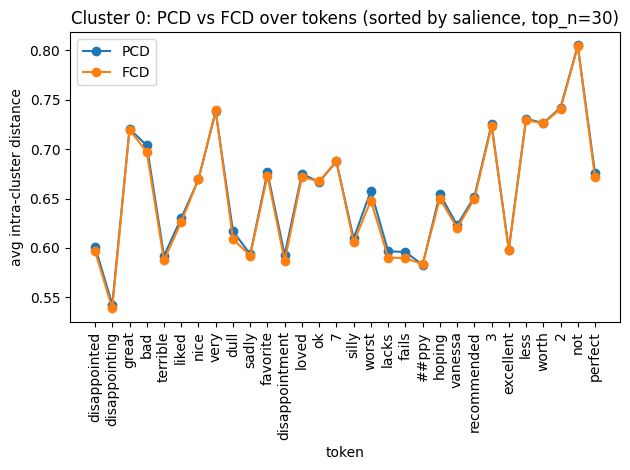

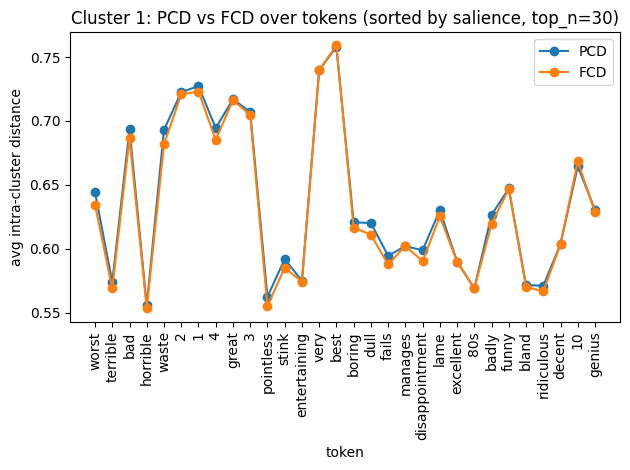

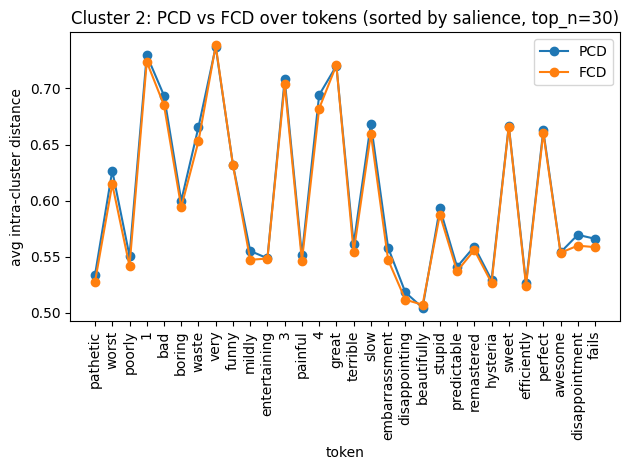

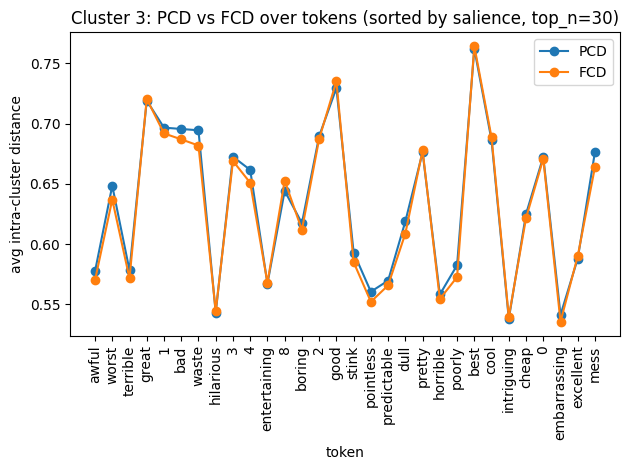

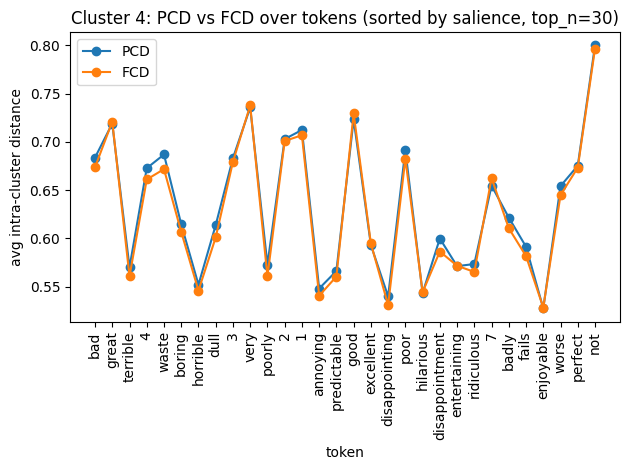

In [44]:
plot_pcd_fcd_over_tokens_per_cluster(
    df_tokens,
    top_n=30,
    sort_by="salience",
    descending=True,
    label_col="token",
    # save_dir = "fcd_vs_pcd"
)

In [45]:
def barplot_delta_per_cluster_sorted_by_delta(
    df_tokens,
    cluster_ids=None,
    top_n=30,
    descending=True,# True => Delta high to low
    label_col="token",# "token" or "token_id"
    max_label_len=16,
    rotation=90,
    save_dir=None, #eg "plots"; None to show
):
    """
    For each cluster: bar plot of Delta = FCD - PCD across tokens,
    tokens sorted by Delta (descending by default). One figure per cluster.
    """
    df = df_tokens.copy()

    if cluster_ids is None:
        cluster_ids = sorted(df["cluster_id"].unique().tolist())

    for cid in cluster_ids:
        d = df[df["cluster_id"] == cid].copy()
        if d.empty:
            continue

        # sort by Delta
        d = d.sort_values("Delta", ascending=not descending)

        # take top_n tokens for readability
        if top_n is not None and len(d) > top_n:
            d = d.head(top_n)

        # labels
        if label_col == "token_id":
            labels = d["token_id"].astype(str).to_numpy()
        else:
            labels = d["token"].astype(str).to_numpy()

        if max_label_len is not None:
            labels = np.array([s if len(s) <= max_label_len else s[:max_label_len-1] + "…" for s in labels])

        x = np.arange(len(d))
        delta = d["Delta"].to_numpy()

        plt.figure()
        plt.bar(x, delta)
        plt.axhline(0.0)
        plt.xticks(x, labels, rotation=rotation)
        plt.xlabel("token" if label_col == "token" else "token_id")
        plt.ylabel("Delta = FCD - PCD")
        order = "descending" if descending else "ascending"
        plt.title(f"Cluster {cid}: Delta over tokens (sorted by Delta {order}, top_n={top_n})")
        plt.tight_layout()

        if save_dir is not None:
            import os
            os.makedirs(save_dir, exist_ok=True)
            outpath = os.path.join(save_dir, f"cluster_{cid}_bar_delta_sorted_by_delta.png")
            plt.savefig(outpath, dpi=200)
            plt.close()
        else:
            plt.show()


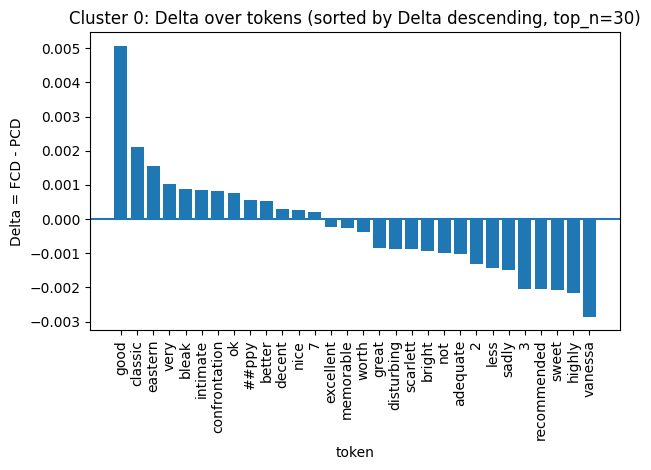

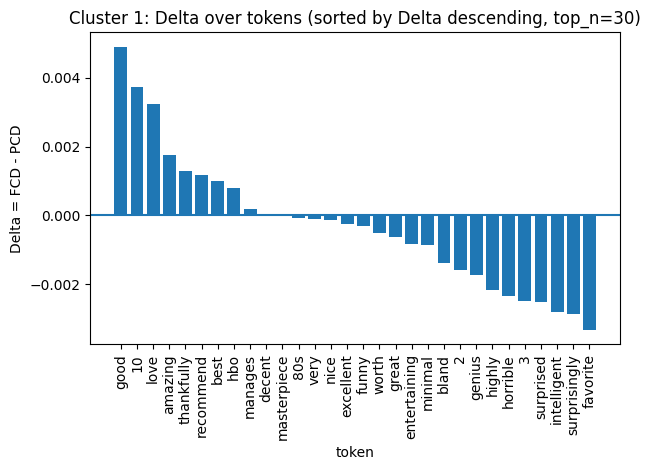

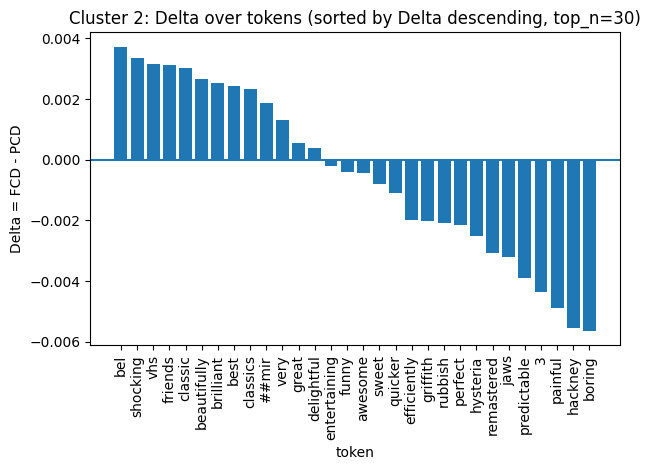

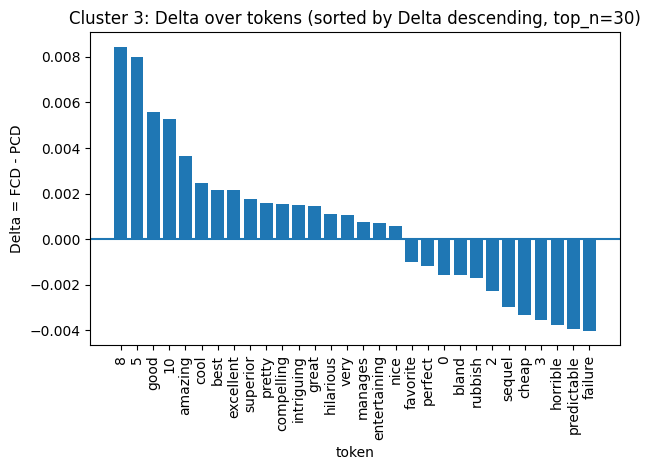

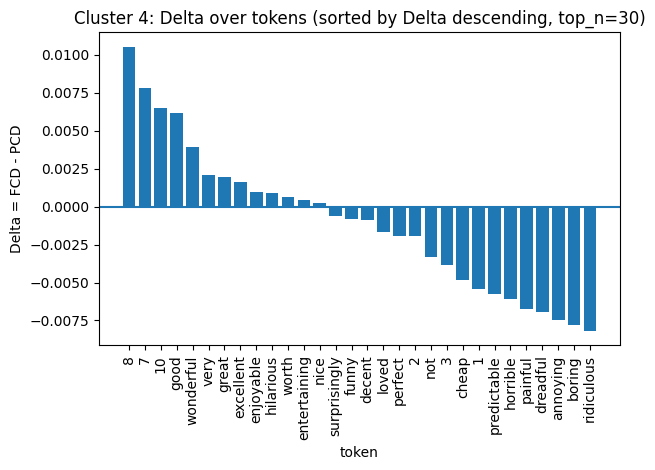

In [46]:
barplot_delta_per_cluster_sorted_by_delta(df_tokens, top_n=30)


In [47]:
def barplot_pcd_fcd_per_cluster_sorted_by_salience(
    df_tokens,
    cluster_ids=None,
    top_n=30,
    label_col="token",# "token" or "token_id"
    max_label_len=16,
    rotation=90,
    save_dir=None,# eg "plots" to save pngs; None to show
    bar_width=0.4,
):
    """
    For each cluster: bar plot with two bars per token (PCD=pretrained, FCD=finetuned),
    tokens sorted by salience descending. One figure per cluster.
    """
    df = df_tokens.copy()

    if cluster_ids is None:
        cluster_ids = sorted(df["cluster_id"].unique().tolist())

    for cid in cluster_ids:
        d = df[df["cluster_id"] == cid].copy()
        if d.empty:
            continue

        # sort by salience (descending)
        d = d.sort_values("salience", ascending=False)

        # take top_n tokens for readability
        if top_n is not None and len(d) > top_n:
            d = d.head(top_n)

        # labels
        if label_col == "token_id":
            labels = d["token_id"].astype(str).to_numpy()
        else:
            labels = d["token"].astype(str).to_numpy()

        if max_label_len is not None:
            labels = np.array([s if len(s) <= max_label_len else s[:max_label_len-1] + "…" for s in labels])

        x = np.arange(len(d))
        w = float(bar_width)

        pcd = d["PCD"].to_numpy()
        fcd = d["FCD"].to_numpy()

        plt.figure()
        plt.bar(x - w/2, pcd, width=w, label="PCD (pretrained)")
        plt.bar(x + w/2, fcd, width=w, label="FCD (finetuned)")
        plt.xticks(x, labels, rotation=rotation)
        plt.xlabel("token" if label_col == "token" else "token_id")
        plt.ylabel("avg intra-cluster distance")
        plt.title(f"Cluster {cid}: PCD vs FCD (tokens sorted by salience, top_n={top_n})")
        plt.legend()
        plt.tight_layout()

        if save_dir is not None:
            import os
            os.makedirs(save_dir, exist_ok=True)
            outpath = os.path.join(save_dir, f"cluster_{cid}_pcd_fcd.png")
            plt.savefig(outpath, dpi=200)
            plt.close()
        else:
            plt.show()


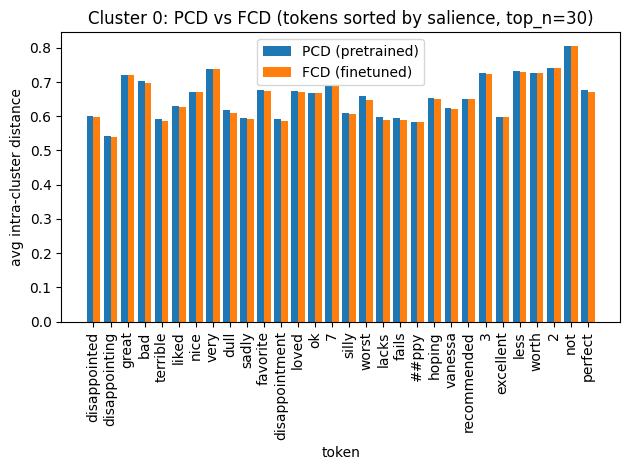

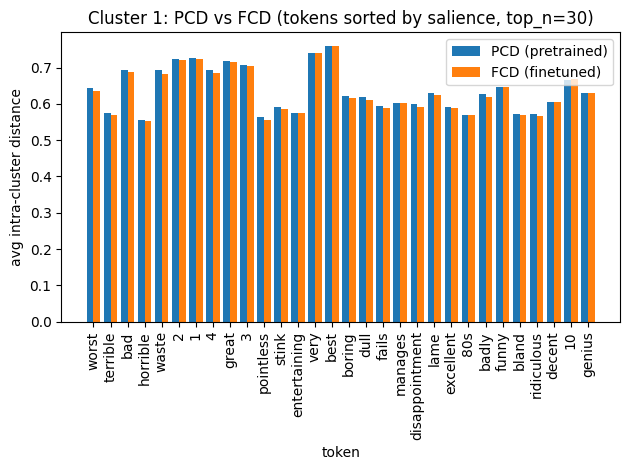

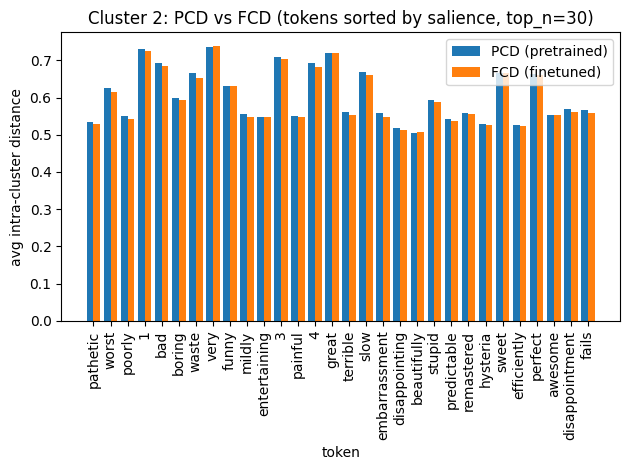

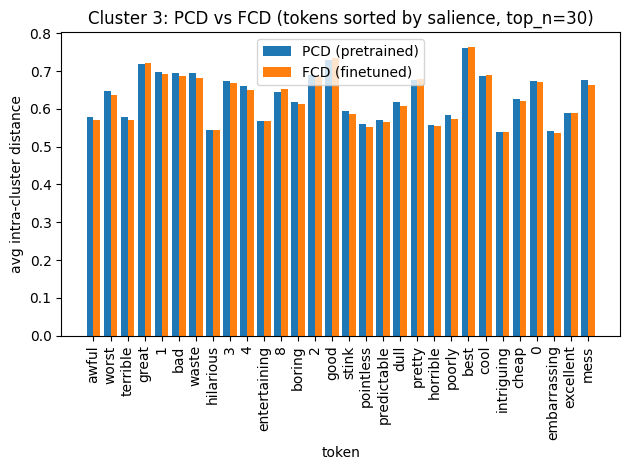

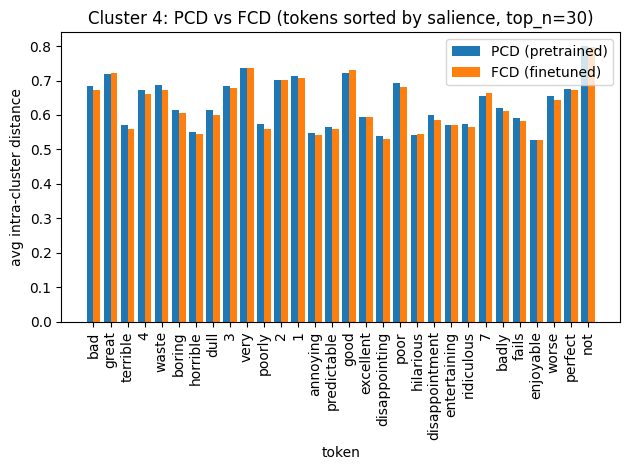

In [48]:
barplot_pcd_fcd_per_cluster_sorted_by_salience(
    df_tokens,
    top_n=30,
    label_col="token",
)


In [49]:
df_tokens[df_tokens["cluster_id"]==4].sort_values(["Delta"],ascending=False).head(20)

,cluster_id,token_id,token,salience,PCD,FCD,Delta,abs_Delta
231,4,1022,8,17.637730,0.652852,0.663388,0.010537,0.010537
223,4,1021,7,21.280226,0.654664,0.662497,0.007833,0.007833
241,4,2184,10,15.088615,0.646341,0.652844,0.006503,0.006503
215,4,2204,good,25.655878,0.723296,0.729452,0.006156,0.006156
237,4,6919,wonderful,15.941236,0.567478,0.571388,0.003910,0.003910
209,4,2200,very,36.066772,0.735716,0.737810,0.002094,0.002094
201,4,2307,great,73.094231,0.719045,0.721023,0.001978,0.001978
216,4,6581,excellent,25.603561,0.593032,0.594658,0.001626,0.001626
226,4,22249,enjoyable,19.204348,0.527257,0.528214,0.000957,0.000957
219,4,26316,hilarious,23.647951,0.543182,0.544098,0.000917,0.000917


In [50]:
df_tokens.sort_values(["Delta"],ascending=False).head(20)

,cluster_id,token_id,token,salience,PCD,FCD,Delta,abs_Delta
231,4,1022,8,17.637730,0.652852,0.663388,0.010537,0.010537
161,3,1022,8,3.311844,0.644234,0.652686,0.008452,0.008452
183,3,1019,5,1.407018,0.656119,0.664095,0.007976,0.007976
223,4,1021,7,21.280226,0.654664,0.662497,0.007833,0.007833
241,4,2184,10,15.088615,0.646341,0.652844,0.006503,0.006503
215,4,2204,good,25.655878,0.723296,0.729452,0.006156,0.006156
164,3,2204,good,2.511407,0.729543,0.735135,0.005592,0.005592
196,3,2184,10,1.238402,0.641117,0.646403,0.005286,0.005286
30,0,2204,good,0.774438,0.728317,0.733385,0.005068,0.005068
80,1,2204,good,2.016188,0.726972,0.731879,0.004906,0.004906
